# Детекция объектов на TensorFlow Lite для микроконтроллеров на Zephyr
### Подготовил: Степанюк Денис Борисович
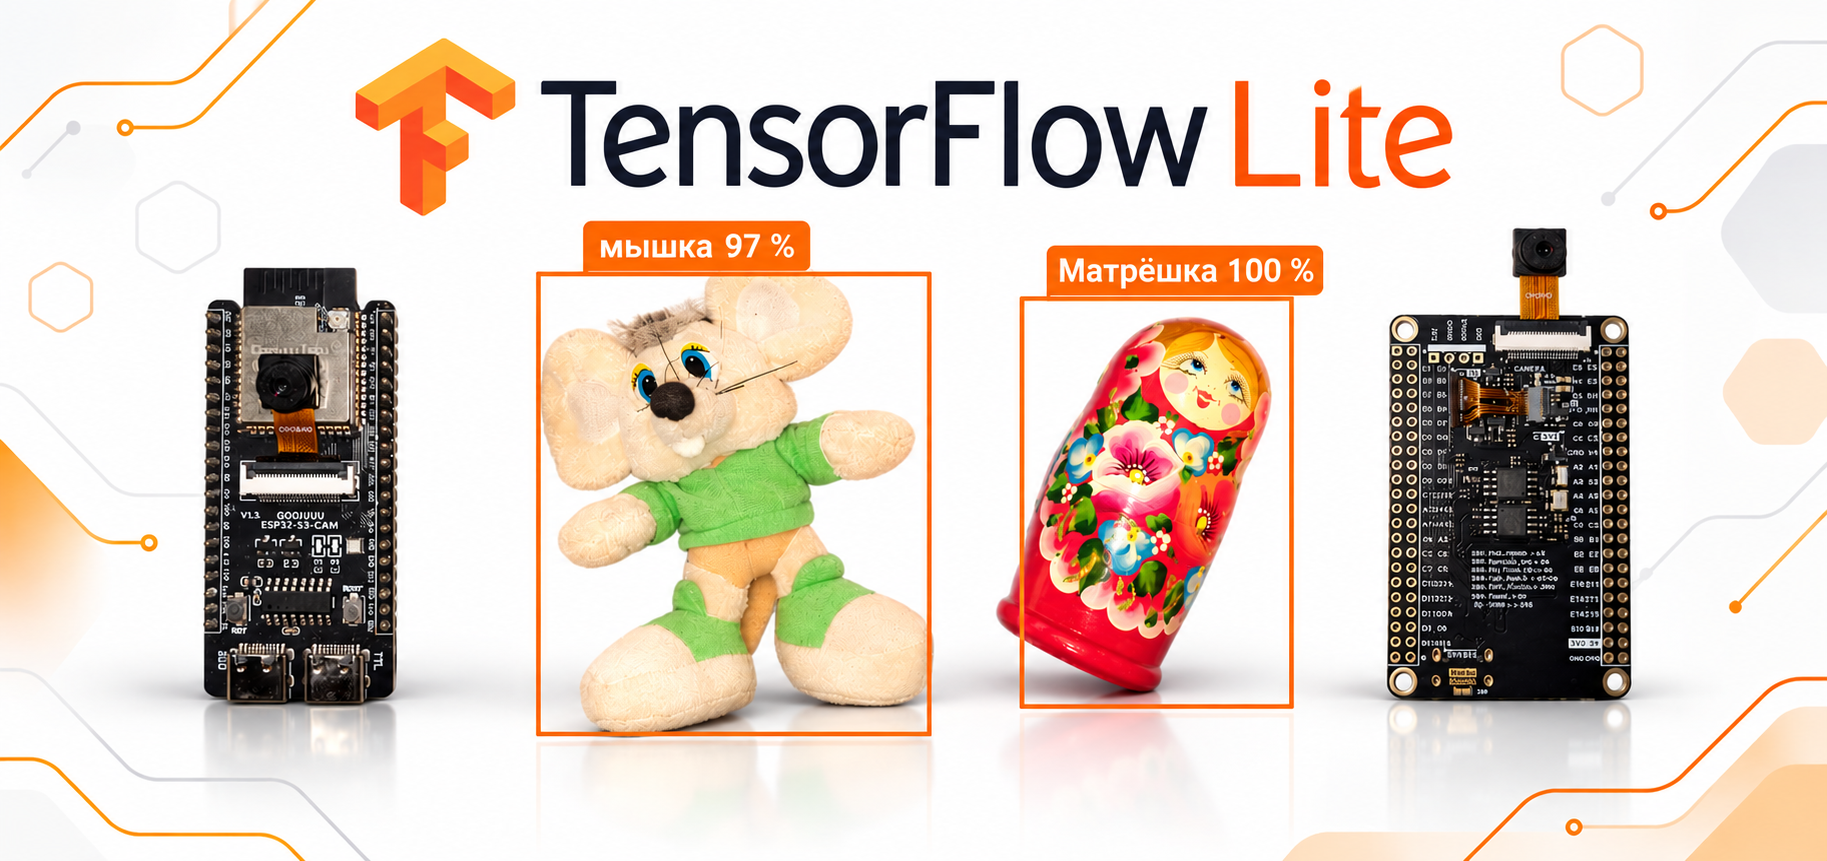

### SSD: Single Shot MultiBox Detector
*  https://arxiv.org/pdf/1512.02325
*  https://github.com/explainingai-code/SSD-PyTorch
*  https://www.youtube.com/watch?v=c_nEue9itwg&list=LL&index=1&t=1s
  
### TTF: Training-Time-Friendly Network:
*  https://arxiv.org/pdf/1909.00700
*  https://github.com/ZJULearning/ttfnet?ysclid=mwf1sge2oy735350010

### Feature Pyramid Networks
*  https://arxiv.org/pdf/1612.03144

### LabelImg
*  https://github.com/HumanSignal/labelImg

*  https://github.com/HumanSignal/labelImg/releases

# Импорт библиотек и модулей

In [1]:
import os, sys, math, json, time, random, copy, hashlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from PIL import Image
from tqdm.auto import tqdm
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Устройства:", tf.config.list_physical_devices())

TensorFlow: 2.13.0
Устройства: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


# Конфигурация проекта
Данный блок кода задает глобальный конфигурационный словарь (CFG), а также инициализирует ключевые глобальные константы и вспомогательные функции для всего пайплайна машинного обучения. Конфигурация охватывает сразу две архитектуры детекторов объектов (SSD и TTFNet), что позволяет гибко управлять гиперпараметрами, аугментацией, стратегией обучения и последующим квантованием модели в формат TensorFlow Lite (TFLite).

In [ ]:
# ======================================================================================
#                                      КОНФИГУРАЦИЯ
# ======================================================================================
CFG = dict(
    paths=dict(
        # Пути к папкам с обучающей, валидационной и тестовой выборками.
        train=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\16_TFL_Detection_SSD\src\python\Datasets\Train_Dataset",
        val=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\16_TFL_Detection_SSD\src\python\Datasets\Validation_Dataset",
        test=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\16_TFL_Detection_SSD\src\python\Datasets\Test_Dataset",
        # Путь к файлу предобученной базовой нейросети
        # backbone=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\16_TFL_Detection_SSD\src\python\model_medium.h5",
        backbone=r"C:\Users\STEPANJUK\Desktop\TFL\TensorFlowLite\TFL_Detection\model_medium.h5",
        # Папка для хранения сгенерированых материалов.
        # out_dir="export",
        out_dir=r"C:\Users\STEPANJUK\Desktop\TFL\TensorFlowLite\TFL_Detection\export_SSD",
    ),
    fg_classes=["matrjona", "mouse"],        # Список целевых классовбез фона; индекс = позиция в списке (0-based)
    img_size=32,                             # Размер входных изображений ($32 \times 32$ пикселя). 
    voc_one_based=True,                      # Указывает, что разметка координат рамок (bounding boxes) в аннотациях из утилиты labelImg.
    archs=["ssd", "ttf"],                    # Указание обучить и сравнить две архитектуры.
    backbone=dict(path_taps=("s1b0_pw_relu6", "s2b0_pw_relu6"), pretrained=True), # Cлои из которых берутся карты признаков в backbone.
    neck_ch=32,                              # Количество каналов в промежуточных слоях FPN(Feature Pyramid Networks) и «головах» предсказателях сетей.
    # Параметры SSD (Single Shot MultiBox Detector)
    ssd=dict(anchors_per_cell=4, # Количество опорных рамок (anchors) разной формы и размера на одну ячейку сетки.
             kmeans_k=6, # Использование алгоритма K-Means для автоматического подбора оптимальных размеров анхоров под ваш датасет.
             pos_iou=0.5, # Порог Intersection over Union (IoU) для определения того, какая рамка считается «положительной» (содержит объект).
             neg_pos_ratio=3, # Соотношение негативных (пустых) примеров к позитивным при вычислении функции потерь (Hard Negative Mining).
             min_neg=16, # минимум негативов на кадр, чтобы фоновые кадры тоже обучали
             variances=(0.1, 0.1, 0.2, 0.2), # Коэффициенты масштабирования для кодирования/декодирования координат рамок.
             w_cls=1.0, # Вес (штраф) для классификации в функции потерь.
             w_l1=1.0, # Вес (штраф) для  регрессии координат (L1) в функции потерь.
             w_giou=2.0), # Вес (штраф) для обобщенного IoU (GIoU) в функции потерь.
    # Параметры TTFNet (Training-Time-Friendly Network)
    ttf=dict(alpha=1.0, w_hm=1.0, # Параметры для функции потерь тепловой карты.
             w_giou=5.0, # Высокий вес GIoU-потерь, так как для TTFNet точное предсказание границ bbox критически важно.
             hm_bias=-3.0), # Начальное смещение (bias) для слоя тепловой карты (для борьбы с тем, что на изображении преобладает фон, а не объекты).
    # Постобработка
    post=dict(conf_thr=0.05, # Минимальный порог уверенности модели, при котором объект вообще рассматривается.
              op_thr=0.30, # Порог для итогового отображения.
              nms_iou=0.45, # Порог Non-Maximum Suppression (подавления не максимумов), чтобы удалять дублирующиеся рамки вокруг одного объекта.
              pre_nms_topk=64, # Брать только топ-64 кандидатов в рамки перед применением NMS (для ускорения).
              max_det=10), # Максимальное количество объектов, которое может быть обнаружено на одном изображении.
    # Аугментация (набор вероятностей)
    aug=dict(p_flip=0.5, # Зеркальное отражение
             p_affine=0.8, # Аффинные преобразования (повороты, сдвиги, масштабирование).
             scale=(0.75, 1.25), # Масштабирование и изменение пропорций.
             aspect=(0.87, 1.15), # Диапазон для случайного изменения соотношения сторон (широты к высоте) изображения.
             shift=0.15,# Максимальную величину смещения изображения по горизонтали (X) и вертикали (Y).
             min_vis=0.45, # объекты с видимой долей < `min_vis` удаляются;
             p_photo=0.9, # Изменение яркости/контраста.
             p_noise=0.4, # Добавление шума.
             p_blur=0.15, # Размытие.
             p_erase=0.25, # Случайное стирание кусков картинки.
             p_mosaic=0.10), # Мозаичная аугментация (склеивание четырех картинок в одну).
    # Параметры обучения
    train=dict(seed=42, # Фиксация генератора случайных чисел для воспроизводимости результатов.
               batch_size=32, # Размер батча (количество картинок за один шаг градиентного спуска).
               epochs=150, # Максимальное количество эпох обучения.
               patience=30, # Количество эпох без улучшений, после которых сработает Early Stopping (остановка обучения во избежание переобучения).
               lr_head=2e-3, # Начальная скорость обучения (learning rate) для «головы» детектора.
               lr_backbone=6e-4, # Начальная скорость обучения (learning rate) отдельно для бэкбона.
               weight_decay=1e-4, # Регуляризация весов (L2-штраф) для борьбы с переобучением.
               warmup_epochs=3, # Разогрев обучения (плавное увеличение learning rate в первые 3 эпохи).
               clip_norm=5.0, # Ограничение градиентов по норме (Gradient Clipping) для предотвращения взрыва градиентов.
               ema_decay=0.995, # Экспоненциальное скользящее среднее весов модели (EMA),
               min_lr_ratio=0.02),# Минимальный предел, до которого может опуститься learning rate при планировании (Cosine Annealing).
    # Количество примеров из валидационного датасета для калибровки при переходе модели в формат INT8 (Post-Training Quantization для TFLite).
    quant=dict(calib_samples=300), 
)
OUT_DIR = Path(CFG["paths"]["out_dir"]); OUT_DIR.mkdir(parents=True, exist_ok=True)
FG = CFG["fg_classes"]; NC = len(FG); IMG = CFG["img_size"]
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

# Функция фиксации генератора случайных чисел для воспроизводимости результатов.
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    try:
        tf.keras.utils.set_random_seed(seed)
    except Exception:
        pass

# Шаг 1. Загрузка датасета
Основная задача этого модуля — считать изображения вместе с их разметкой в формате Pascal VOC (XML), привести координаты ограничивающих рамок (bounding boxes) к единому нормализованному формату, отфильтровать битые или некорректные примеры, а также корректно обработать фоновые кадры (изображения без объектов).

In [3]:
# Преобразование координат рамок из формата Pascal VOC указывающего координаты рамки (xmin, ymin, xmax, ymax) в виде целых чисел пикселей, 
# в нормализованные координаты в диапазоне от 0.0 до 1.0.
def voc_box_to_xyxy(xmin, ymin, xmax, ymax, w, h, one_based=True):
    b = 1.0 if one_based else 0.0
    x1, y1 = xmin - b, ymin - b
    x2, y2 = xmax - b + 1.0, ymax - b + 1.0
    return np.clip(np.array([x1 / w, y1 / h, x2 / w, y2 / h], np.float32), 0.0, 1.0)

# Загрузка датасета: функция рекурсивно обходит указанную папку (root), находит все изображения и сопоставляет им XML-файлы с разметкой.
def load_split(root, fg_classes=FG, one_based=True, size=IMG, min_px=1.0, verbose=True):
    """Возвращает dict: images uint8 [N,S,S,3], boxes list[[n,4] xyxy], labels list[[n] int32 0-based], paths."""
    root = Path(root); name2idx = {c.lower(): i for i, c in enumerate(fg_classes)}
    images, boxes, labels, paths = [], [], [], []
    skipped = dict(no_xml=0, unknown_cls=0, degenerate=0, bad_size=0); n_bg = 0
    if not root.exists():
        print(f"[!] Путь не найден: {root}"); 
    for dp, _, files in sorted(os.walk(root)):
        for fn in sorted(files):
            stem, ext = os.path.splitext(fn)
            if ext.lower() not in IMG_EXTS: continue
            ip = Path(dp) / fn; xp = Path(dp) / (stem + ".xml")
            is_bg_dir = "background" in [p.lower() for p in Path(dp).relative_to(root).parts]
            img = Image.open(ip).convert("RGB")
            if img.size != (size, size):
                skipped["bad_size"] += 1
                if skipped["bad_size"] == 1:
                    print(f"[!] {ip} имеет размер {img.size}, ожидается {(size, size)} — файл пропущен")
                continue
            W, H = img.size; bxs, lbs = [], []; bad_obj = False
            if xp.exists():
                for obj in ET.parse(xp).getroot().findall("object"):
                    nm = obj.find("name").text.strip().lower()
                    if nm not in name2idx: bad_obj = True; continue
                    bb = obj.find("bndbox")
                    xyxy = voc_box_to_xyxy(*[float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")],
                                           W, H, one_based)
                    if (xyxy[2] - xyxy[0]) * W < min_px or (xyxy[3] - xyxy[1]) * H < min_px:
                        skipped["degenerate"] += 1; continue
                    bxs.append(xyxy); lbs.append(name2idx[nm])
                if bad_obj and not bxs:
                    skipped["unknown_cls"] += 1; continue
            elif not is_bg_dir:
                skipped["no_xml"] += 1; continue
            if not bxs: n_bg += 1
            images.append(np.asarray(img, np.uint8)); paths.append(str(ip))
            boxes.append(np.array(bxs, np.float32).reshape(-1, 4)); labels.append(np.array(lbs, np.int32))
    data = dict(images=np.stack(images) if images else np.zeros((0, size, size, 3), np.uint8),
                boxes=boxes, labels=labels, paths=paths)
    if verbose:
        cnt = np.bincount(np.concatenate(labels) if labels and sum(map(len, labels)) else np.zeros(0, int),
                          minlength=len(fg_classes))
        print(f"{root.name:>20}: кадров {len(images)} (фон {n_bg}) | объектов по классам "
              f"{dict(zip(fg_classes, cnt.tolist()))} | пропущено {skipped}")
    return data

In [4]:
train_data = load_split(CFG["paths"]["train"], FG, CFG["voc_one_based"])
val_data   = load_split(CFG["paths"]["val"],   FG, CFG["voc_one_based"])
test_data  = load_split(CFG["paths"]["test"],  FG, CFG["voc_one_based"])
assert len(train_data["images"]) > 0, "Проверьте пути в CFG['paths']"

       Train_Dataset: кадров 2278 (фон 645) | объектов по классам {'matrjona': 1010, 'mouse': 995} | пропущено {'no_xml': 0, 'unknown_cls': 0, 'degenerate': 0, 'bad_size': 0}
  Validation_Dataset: кадров 330 (фон 100) | объектов по классам {'matrjona': 130, 'mouse': 130} | пропущено {'no_xml': 0, 'unknown_cls': 0, 'degenerate': 0, 'bad_size': 0}
        Test_Dataset: кадров 330 (фон 100) | объектов по классам {'matrjona': 130, 'mouse': 130} | пропущено {'no_xml': 0, 'unknown_cls': 0, 'degenerate': 0, 'bad_size': 0}


### Статистика данных и визуальная проверка боксов
Данный блок кода отвечает за анализ геометрических характеристик датасета (распределение размеров ограничивающих рамок) и визуальный контроль качества разметки, проверки того, что координаты bounding boxes корректно накладываются на изображения объектов.

Размеры боксов (доли кадра): w медиана 0.53 [0.19..1.00], h медиана 0.69 [0.25..1.00]


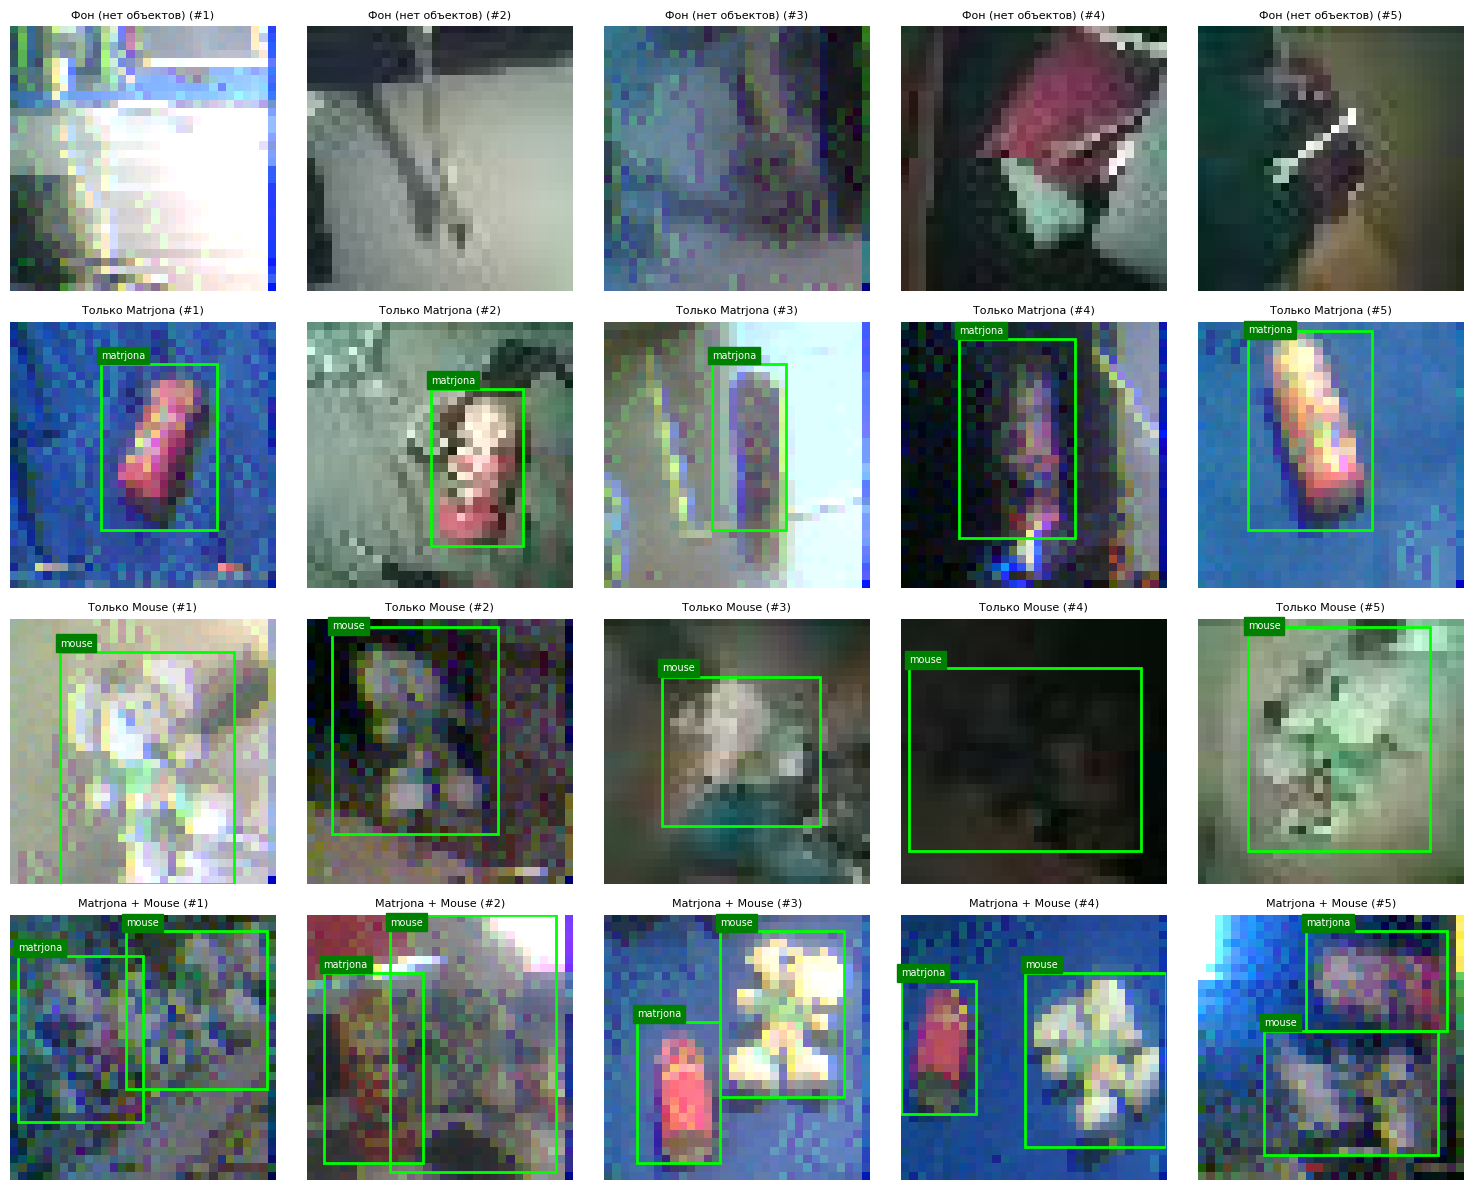

In [5]:
# Функция предназначена для сбора статистической информации о размерах 
# всех ограничивающих рамок (bounding boxes) в переданном наборе данных.
# Она вычисляет ширину и высоту каждой рамки и объединяет их в единый массив.
def box_stats(data):
    wh = np.concatenate([(b[:, 2:] - b[:, :2]) for b in data["boxes"] if len(b)], 0)
    return wh  # [N,2] (w,h) в долях изображения

# Функция предназначена для демонстрационной визуализации тренеровочных данных.
def show_categorized_samples(data, fg_classes=FG, seed=0):
    rng = np.random.default_rng(seed)
    
    # 1. Распределяем индексы изображений по категориям
    bg_idx = [i for i, b in enumerate(data["boxes"]) if len(b) == 0]
    matrjona_only_idx = [i for i, (b, l) in enumerate(zip(data["boxes"], data["labels"])) 
                           if len(b) > 0 and 0 in l and 1 not in l]
    mouse_only_idx = [i for i, (b, l) in enumerate(zip(data["boxes"], data["labels"])) 
                        if len(b) > 0 and 1 in l and 0 not in l]
    both_idx = [i for i, (b, l) in enumerate(zip(data["boxes"], data["labels"])) 
                if len(b) > 0 and 0 in l and 1 in l]
    
    # Формируем список категорий для отображения по строкам
    categories = [
        ("Фон (нет объектов)", bg_idx),
        ("Только Matrjona", matrjona_only_idx),
        ("Только Mouse", mouse_only_idx),
        ("Matrjona + Mouse", both_idx)
    ]
    
    # Создаем сетку графиков: 4 строки, 5 колонок
    fig, axes = plt.subplots(4, 5, figsize=(15, 12))
    
    for row_idx, (cat_name, indices) in enumerate(categories):
        # Выбираем до 5 случайных уникальных индексов (если элементов достаточно)
        n_samples = min(5, len(indices))
        chosen = rng.choice(indices, size=n_samples, replace=False) if n_samples > 0 else []
        
        for col_idx in range(5):
            ax = axes[row_idx, col_idx]
            ax.axis("off") # Скрываем оси координат по умолчанию
            
            if col_idx < len(chosen):
                i = chosen[col_idx]
                # Выводим саму картинку
                ax.imshow(data["images"][i], extent=(0, 1, 1, 0), interpolation="nearest")
                
                # Рисуем рамки (bounding boxes) и подписи классов
                for b, l in zip(data["boxes"][i], data["labels"][i]):
                    ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], 
                                              fill=False, ec="lime", lw=2))
                    ax.text(b[0], max(b[1] - 0.02, 0.04), fg_classes[l], 
                            color="white", backgroundcolor="green", fontsize=7)
                
                ax.set_title(f"{cat_name} (#{col_idx+1})", fontsize=8)
            else:
                # Если в датасете не хватило картинок для заполнения ряда до 5 штук
                ax.set_title(f"{cat_name}\n(нет примеров)", fontsize=8)
                
    plt.tight_layout()
    plt.show()

# Статистика боксов и вызов новой визуализации
wh_train = box_stats(train_data)
print("Размеры боксов (доли кадра): w медиана %.2f [%.2f..%.2f], h медиана %.2f [%.2f..%.2f]" % (
    np.median(wh_train[:, 0]), wh_train[:, 0].min(), wh_train[:, 0].max(),
    np.median(wh_train[:, 1]), wh_train[:, 1].min(), wh_train[:, 1].max()))

show_categorized_samples(train_data, FG, seed=42)

# Шаг 2. Аугментация
Данный блок кода реализует модуль аугментации данных (Data Augmentation), написанный на чистом NumPy и оптимизированный для работы с тензорами изображений небольшого разрешения ($32 \times 32$ float [0, 1]) и их ограничивающими рамками (bounding boxes). Аугментация критически важна для предотвращения переобучения (overfitting), повышения устойчивости нейросетей к изменениям масштаба, освещения, углов обзора, а также для имитации шумов реальных датчиков камер.

* Горизонтальное зеркальное отражение изображения
* Аффинные преобразования (масштабирование, сдвиг, изменение пропорций)
* Искажение фотометрических характеристик изображений (яркость, контраст, насыщенность, баланс белого, гамму, шум и размытие)
* Случайным образом закрашивается шумом прямоугольный участок изображения
* Создается мозаика из четырех изображений
* Объединяется все выбранные методы аугментации в единый пайплайн для обработки одного изображения

In [6]:
# Ограничивает координаты рамок (bounding boxes) в пределах допустимого диапазона от 0.0 до 1.0.
def _clip_boxes(b):
    return np.clip(b, 0.0, 1.0)

# Вычисляет площадь ограничивающих рамок по их координатам.
def _area(b):
    return np.maximum(b[..., 2] - b[..., 0], 0) * np.maximum(b[..., 3] - b[..., 1], 0)

# Выполняет горизонтальное зеркальное отражение изображения и пересчитывает координаты рамок.
def hflip(img, boxes):
    img = img[:, ::-1]
    if len(boxes):
        boxes = boxes.copy(); boxes[:, [0, 2]] = 1.0 - boxes[:, [2, 0]]
    return np.ascontiguousarray(img), boxes

# Применяет аффинные преобразования (масштабирование, сдвиг, изменение пропорций) к изображению и объектам 
# с проверкой видимости рамок после трансформации.
def affine_aug(img, boxes, labels, sx, sy, tx, ty, min_vis=0.45, min_side=1.5 / IMG):
    """Прямое преобразование норм. координат: x' = (x-.5)*sx+.5+tx. Возвращает (img', boxes', labels')."""
    H, W = img.shape[:2]
    # inverse mapping для выходных пикселей (по центрам)
    u = (np.arange(W) + 0.5) / W; v = (np.arange(H) + 0.5) / H
    xs = ((u - 0.5 - tx) / sx + 0.5) * W - 0.5     # индексное пространство входа
    ys = ((v - 0.5 - ty) / sy + 0.5) * H - 0.5
    valid = (xs[None, :] >= -0.5) & (xs[None, :] <= W - 0.5) & (ys[:, None] >= -0.5) & (ys[:, None] <= H - 0.5)
    x0 = np.clip(np.floor(xs).astype(int), 0, W - 1); x1 = np.clip(x0 + 1, 0, W - 1)
    y0 = np.clip(np.floor(ys).astype(int), 0, H - 1); y1 = np.clip(y0 + 1, 0, H - 1)
    wx = np.clip(xs - np.floor(xs), 0, 1)[None, :, None]; wy = np.clip(ys - np.floor(ys), 0, 1)[:, None, None]
    top = img[y0][:, x0] * (1 - wx) + img[y0][:, x1] * wx
    bot = img[y1][:, x0] * (1 - wx) + img[y1][:, x1] * wx
    out = top * (1 - wy) + bot * wy
    fill = img.reshape(-1, 3).mean(0)
    out = np.where(valid[..., None], out, fill[None, None, :]).astype(np.float32)
    if len(boxes) == 0:
        return out, boxes, labels
    nb = boxes.copy()
    nb[:, [0, 2]] = (boxes[:, [0, 2]] - 0.5) * sx + 0.5 + tx
    nb[:, [1, 3]] = (boxes[:, [1, 3]] - 0.5) * sy + 0.5 + ty
    full = _area(nb); cb = _clip_boxes(nb); vis = _area(cb) / np.maximum(full, 1e-9)
    keep = (vis >= min_vis) & ((cb[:, 2] - cb[:, 0]) >= min_side) & ((cb[:, 3] - cb[:, 1]) >= min_side)
    return out, cb[keep].astype(np.float32), labels[keep]

# Искажает фотометрические характеристики изображения (яркость, контраст, насыщенность, баланс белого, гамму, шум и размытие).
def photometric(img, rng, a):
    x = img
    if rng.random() < a["p_photo"]:
        x = x + rng.uniform(-0.2, 0.2)                                   # яркость
        m = x.mean(); x = (x - m) * rng.uniform(0.7, 1.3) + m             # контраст
        g = x.mean(-1, keepdims=True); x = g + (x - g) * rng.uniform(0.6, 1.4)   # насыщенность
        x = x * rng.uniform(0.92, 1.08, size=(1, 1, 3))                   # баланс белого
        x = np.clip(x, 0, 1) ** rng.uniform(0.75, 1.35)                   # гамма
    if rng.random() < a["p_noise"]:
        x = x + rng.normal(0, rng.uniform(0.005, 0.04), x.shape)
    if rng.random() < a["p_blur"]:
        p = np.pad(x, ((1, 1), (1, 1), (0, 0)), mode="edge")
        x = (p[:-2, 1:-1] + p[2:, 1:-1] + p[1:-1, :-2] + p[1:-1, 2:] + 4 * p[1:-1, 1:-1]) / 8.0
    return np.clip(x, 0, 1).astype(np.float32)

# Случайным образом стирает (закрашивает шумом) прямоугольный участок изображения, не перекрывая полностью целевые объекты.
def random_erase(img, boxes, rng, tries=5):
    H, W = img.shape[:2]
    for _ in range(tries):
        area = rng.uniform(0.03, 0.12) * H * W; ar = rng.uniform(0.5, 2.0)
        h = int(round(math.sqrt(area / ar))); w = int(round(math.sqrt(area * ar)))
        if h < 2 or w < 2 or h >= H or w >= W: continue
        y = rng.integers(0, H - h + 1); x = rng.integers(0, W - w + 1)
        e = np.array([x / W, y / H, (x + w) / W, (y + h) / H], np.float32)
        ok = True
        for b in boxes:
            iw = max(0.0, min(b[2], e[2]) - max(b[0], e[0])); ih = max(0.0, min(b[3], e[3]) - max(b[1], e[1]))
            if iw * ih > 0.5 * _area(b): ok = False; break
        if ok:
            img = img.copy(); img[y:y + h, x:x + w] = rng.uniform(0, 1, size=(1, 1, 3)) + rng.normal(0, 0.05, (h, w, 3))
            return np.clip(img, 0, 1).astype(np.float32)
    return img

# Объединяет все выбранные методы аугментации (отражение, аффинные трансформации, фотометрию и стирание) 
# в единый пайплайн для обработки одного изображения.
def augment_one(img, boxes, labels, rng, a):
    """img float32 [S,S,3] 0..1; boxes xyxy norm; возвращает аугментированную тройку."""
    had = len(boxes) > 0
    if rng.random() < a["p_flip"]:
        img, boxes = hflip(img, boxes)
    if rng.random() < a["p_affine"]:
        s = rng.uniform(*a["scale"]); asp = rng.uniform(*a["aspect"])
        sx, sy = s * asp, s / asp
        tx, ty = rng.uniform(-a["shift"], a["shift"], 2)
        i2, b2, l2 = affine_aug(img, boxes, labels, sx, sy, tx, ty, a["min_vis"])
        if (not had) or len(b2) > 0:
            img, boxes, labels = i2, b2, l2
    img = photometric(img, rng, a)
    if rng.random() < a["p_erase"]:
        img = random_erase(img, boxes, rng)
    return img, boxes.astype(np.float32), labels

# Создает мозаику из четырех изображений, уменьшая их вдвое и объединяя их в единый кадр вместе с пересчитанными координатами рамок.
def mosaic4(samples):
    """samples: 4 тройки (img float, boxes, labels) → 2×2 мозаика с уменьшением вдвое (area-average)."""
    S = samples[0][0].shape[0]; h = S // 2
    out = np.zeros_like(samples[0][0]); bxs, lbs = [], []
    for k, (im, b, l) in enumerate(samples):
        small = im.reshape(h, 2, h, 2, 3).mean((1, 3))
        oy, ox = (k // 2) * h, (k % 2) * h
        out[oy:oy + h, ox:ox + h] = small
        if len(b):
            nb = b * 0.5; nb[:, [0, 2]] += ox / S; nb[:, [1, 3]] += oy / S
            bxs.append(nb); lbs.append(l)
    if bxs: return out, np.concatenate(bxs).astype(np.float32), np.concatenate(lbs).astype(np.int32)
    return out, np.zeros((0, 4), np.float32), np.zeros(0, np.int32)

### Визуальный контроль качества аугментаций
Поскольку геометрические преобразования (аффинные сдвиги, зеркалирование) одновременно меняют положение изображений и координаты ограничивающих рамок (bounding boxes), крайне важно убедиться в отсутствии математических ошибок. Функция строит сетку изображений, где исходный кадр сравнивается с серией его аугментированных версий, позволяя наглядно проконтролировать корректность наложения зеленых рамок (lime) на целевые объекты.

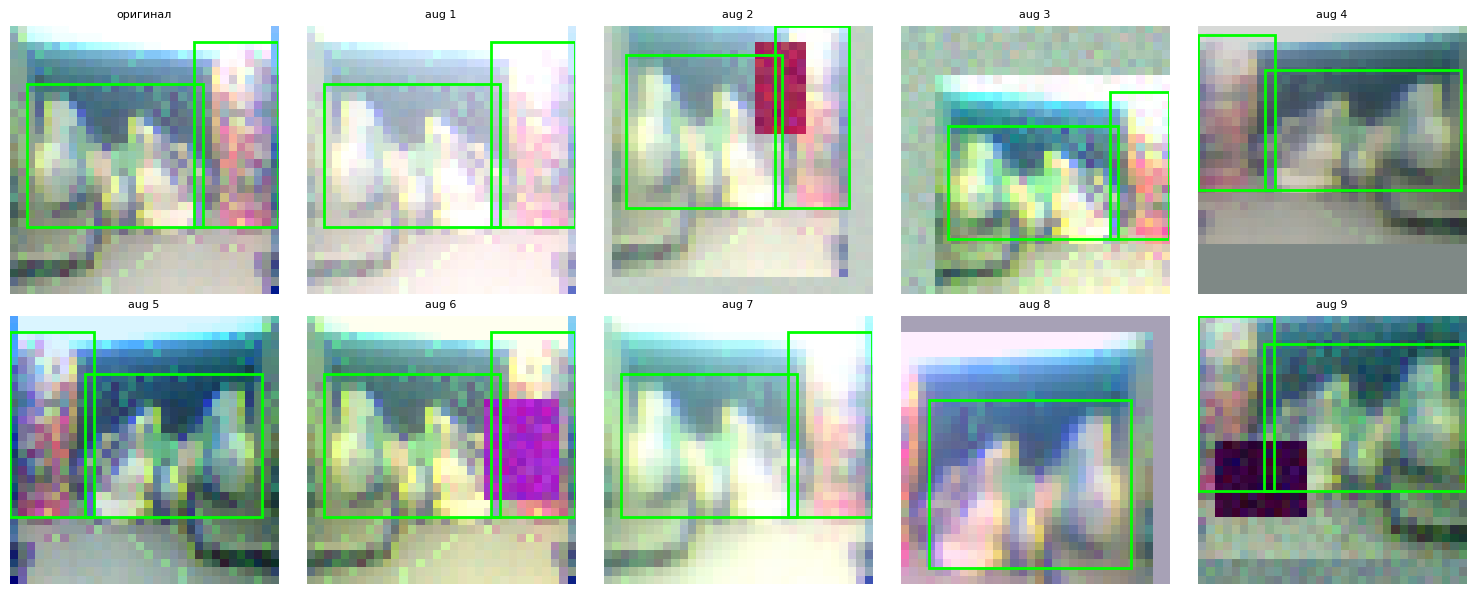

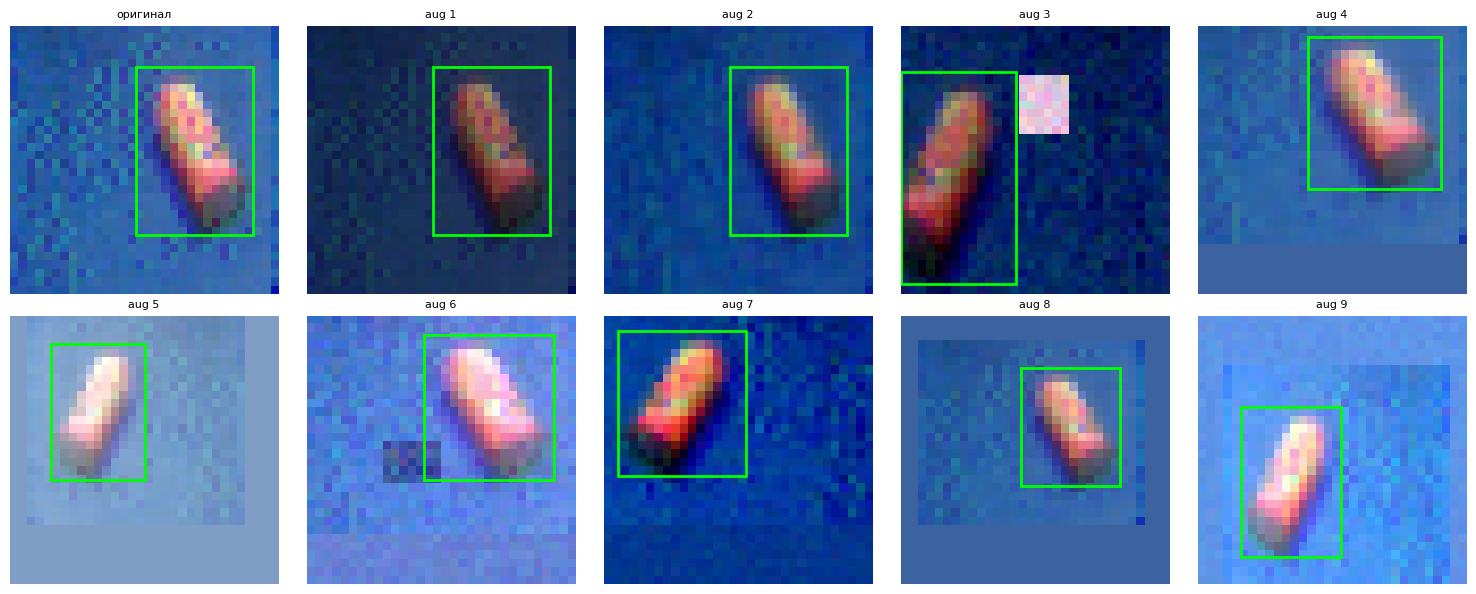

In [7]:
def show_augmentations(data, idx=0, n=10, seed=1):
    rng = np.random.default_rng(seed)
    img0 = data["images"][idx].astype(np.float32) / 255.0; b0, l0 = data["boxes"][idx], data["labels"][idx]
    fig, axes = plt.subplots(2, n // 2, figsize=(3 * n // 2, 6))
    for k, ax in enumerate(axes.ravel()):
        im, b, l = (img0, b0, l0) if k == 0 else augment_one(img0, b0, l0, rng, CFG["aug"])
        ax.imshow(im, extent=(0, 1, 1, 0), interpolation="nearest"); ax.axis("off")
        for bb in b: ax.add_patch(plt.Rectangle((bb[0], bb[1]), bb[2] - bb[0], bb[3] - bb[1], fill=False, ec="lime", lw=2))
        ax.set_title("оригинал" if k == 0 else f"aug {k}", fontsize=8)
    plt.tight_layout(); plt.show()

fg_idx = [i for i, b in enumerate(train_data["boxes"]) if len(b)]
show_augmentations(train_data, fg_idx[0]); show_augmentations(train_data, fg_idx[len(fg_idx) // 2], seed=5)

# Шаг 3. Реализация функций постпроцессинга для детекторов объектов

* **Геометрические расчеты: пересечение рамок (IoU):**

Метрика IoU (Intersection over Union): Вычисляет матрицу пересечений над объединением между набором истинных рамок a (Ground Truth) и набором предсказанных/опорных рамок b.
* **Кластеризация анхоров: метод K-Means:**

Автоматический подбор размеров: Вместо ручного задания фиксированных пропорций анхоров, алгоритм кластеризует реальные размеры (width, height) объектов из датасета.
* **Управление сеткой и уровнями пирамиды признаков:**

Распределяет кластеризованные центры размеров анхоров по разным уровням сетки (например, разрешениям $8 \times 8$ и $4 \times 4$), используя перекрывающиеся окна.
* **Кодирование и декодирование смещений рамок:**

Превращает абсолютные координаты реальных объектов (gt) относительно опорных рамок (anc) в масштабированные дельты с учетом дисперсий (var), облегчая процесс обучения регрессора сети.
* **Формирование целевых меток для SSD:**

Для каждого кадра сопоставляет реальные объекты с опорными рамками на основе матрицы IoU.
* **Формирование тепловых карт и регрессии для TTFNet:**

Генерирует гауссовы тепловые карты (hm) центров объектов на сетке $H \times W$ и рассчитывает целевые расстояния от центра ячейки до четырех сторон рамки (ltrb: left, top, right, bottom).
* **Постобработка: подавление немаксимумов (NMS) и декодеры предсказаний:**
  - NMS (batched_nms_np): Жадный алгоритм подавления пересекающихся дублирующихся рамок внутри одного класса, если их IoU превышает порог thr.

  - Декодеры (decode_ssd_np, decode_ttf_np): Превращают сырые логиты нейросети (вероятности классов, дельты для SSD или пики тепловых карт и смещения ltrb для TTFNet) в итоговые списки обнаруженных объектов, фильтруя их по порогу уверенности (conf_thr) и максимальному числу детекций (max_det).
 
* **Метрики качества детекции (mAP, Precision, Recall, F1, mIoU)**

In [8]:
DELTA_CLIP = 2.5   # |dw*var|,|dh*var| ≤ 2.5 → масштаб ×[0.08, 12.2] (то же в TF и C)

# Вычисляет матрицу коэффициентов пересечения над объединением (Intersection over Union) между двумя наборами рамок.
def iou_np(a, b):
    """a:[G,4], b:[A,4] (xyxy) → [G,A]."""
    a = np.asarray(a, np.float32).reshape(-1, 4); b = np.asarray(b, np.float32).reshape(-1, 4)
    lt = np.maximum(a[:, None, :2], b[None, :, :2]); rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(-1)
    ua = _area(a)[:, None] + _area(b)[None, :] - inter
    return inter / np.maximum(ua, 1e-9)

# ---------------------------------- k-means anchors -----------------------------------
# Подбирает оптимальные размеры базовых рамок (anchors) под размеры объектов датасета методом кластеризации K-Means.
def kmeans_wh(wh, k, iters=300, seed=0):
    wh = np.asarray(wh, np.float64); rng = np.random.default_rng(seed)
    if len(wh) < k:
        wh = np.concatenate([wh, wh[rng.integers(0, len(wh), k - len(wh))] * rng.uniform(0.9, 1.1, (k - len(wh), 2))])
    # k-means++-подобная инициализация по расстоянию 1-IoU
    def d_iou(x, c):
        inter = np.minimum(x[:, None, 0], c[None, :, 0]) * np.minimum(x[:, None, 1], c[None, :, 1])
        return 1 - inter / (x[:, 0:1] * x[:, 1:2] + (c[:, 0] * c[:, 1])[None, :] - inter)
    cent = [wh[rng.integers(len(wh))]]
    while len(cent) < k:
        d = d_iou(wh, np.array(cent)).min(1) ** 2
        cent.append(wh[rng.choice(len(wh), p=d / d.sum())] if d.sum() > 0 else wh[rng.integers(len(wh))])
    cent = np.array(cent)
    for _ in range(iters):
        asg = d_iou(wh, cent).argmin(1); new = cent.copy()
        for j in range(k):
            if (asg == j).any(): new[j] = np.median(wh[asg == j], axis=0)
        if np.allclose(new, cent, atol=1e-6): break
        cent = new
    cent = cent[np.argsort(cent[:, 0] * cent[:, 1])]
    mean_iou = float((1 - d_iou(wh, cent).min(1)).mean())
    return cent.astype(np.float32), mean_iou

# Распределяет найденные кластеры размеров рамок по разным уровням пирамиды признаков (FPN).
def level_anchor_sets(centers, n_levels, per_cell):
    """centers отсортированы по площади; уровень l получает окно из per_cell центров (перекрывающиеся окна)."""
    k = len(centers); assert per_cell <= k
    starts = np.round(np.linspace(0, k - per_cell, n_levels)).astype(int)
    return [centers[s:s + per_cell] for s in starts]

# Генерирует полную сетку опорных рамок (anchors) для всех ячеек и уровней в форматах центра/размера (cxcywh) и углов (xyxy).
def build_ssd_anchors(grids, level_wh):
    """grids=[(H,W),...]; level_wh=[[A,2],...] → (cxcywh [N,4], xyxy [N,4]); порядок (строка, столбец, anchor)."""
    out = []
    for (H, W), wh in zip(grids, level_wh):
        cy, cx = np.meshgrid((np.arange(H) + 0.5) / H, (np.arange(W) + 0.5) / W, indexing="ij")
        A = len(wh)
        c = np.stack([np.repeat(cx.reshape(-1), A), np.repeat(cy.reshape(-1), A)], -1)
        s = np.tile(wh, (H * W, 1)); out.append(np.concatenate([c, s], 1))
    cxcywh = np.concatenate(out, 0).astype(np.float32)
    xyxy = np.concatenate([cxcywh[:, :2] - cxcywh[:, 2:] / 2, cxcywh[:, :2] + cxcywh[:, 2:] / 2], 1)
    return cxcywh, xyxy.astype(np.float32)

# Кодирует смещения реальных объектов (ground truth) относительно опорных рамок в нормированные дельты для обучения SSD.
def encode_np(gt, anc, var):
    gw, gh = gt[:, 2] - gt[:, 0], gt[:, 3] - gt[:, 1]; gcx, gcy = gt[:, 0] + gw / 2, gt[:, 1] + gh / 2
    return np.stack([(gcx - anc[:, 0]) / (anc[:, 2] * var[0]), (gcy - anc[:, 1]) / (anc[:, 3] * var[1]),
                     np.log(np.maximum(gw, 1e-6) / anc[:, 2]) / var[2], np.log(np.maximum(gh, 1e-6) / anc[:, 3]) / var[3]], -1)

# Декодирует предсказанные моделью дельты обратно в реальные координаты рамок (xyxy).
def decode_np(d, anc, var, clip=True):
    cx = anc[:, 0] + d[:, 0] * var[0] * anc[:, 2]; cy = anc[:, 1] + d[:, 1] * var[1] * anc[:, 3]
    w = anc[:, 2] * np.exp(np.clip(d[:, 2] * var[2], -DELTA_CLIP, DELTA_CLIP))
    h = anc[:, 3] * np.exp(np.clip(d[:, 3] * var[3], -DELTA_CLIP, DELTA_CLIP))
    b = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)
    return np.clip(b, 0, 1) if clip else b

# Формирует целевые тензоры (метки классов, кодированные смещения и маски позитивных примеров) для обучения модели SSD.
def ssd_targets(boxes, labels, anc_cxcywh, anc_xyxy, c):
    """Целевые тензоры SSD для одного кадра. cls: 0=фон, 1..NC; loc — кодированные дельты; gtbox — сырой GT для GIoU."""
    A = len(anc_cxcywh)
    t = dict(cls=np.zeros(A, np.int32), loc=np.zeros((A, 4), np.float32), gtbox=np.zeros((A, 4), np.float32),
             pos=np.zeros(A, np.float32))
    if len(boxes) == 0: return t
    iou = iou_np(boxes, anc_xyxy)                      # [G,A]
    best_g = iou.argmax(0); best_i = iou.max(0)
    for g in range(len(boxes)):                        # гарантированные + равные по IoU «лучшие» anchors для каждого GT
        mx = iou[g].max()
        if mx <= 0: continue
        idx = np.where(iou[g] >= mx - 1e-6)[0]; best_g[idx] = g; best_i[idx] = 2.0
    m = best_i >= c["pos_iou"]
    if m.any():
        g = best_g[m]; t["pos"][m] = 1.0; t["cls"][m] = labels[g] + 1
        t["gtbox"][m] = boxes[g]; t["loc"][m] = encode_np(boxes[g], anc_cxcywh[m], c["variances"])
    return t

# Формирует целевые тензоры (гауссовы тепловые карты центров, расстояния до границ ltrb и веса) для обучения модели TTFNet.
def ttf_targets(boxes, labels, grid, nc, alpha=1.0):
    """heatmap [H,W,nc], reg(l,t,r,b в долях кадра) [H,W,4], wgt [H,W] (сумма по каждому объекту = 1)."""
    H, W = grid
    hm = np.zeros((H, W, nc), np.float32); reg = np.zeros((H, W, 4), np.float32); wgt = np.zeros((H, W), np.float32)
    owner = -np.ones((H, W), int)
    if len(boxes) == 0: return dict(hm=hm, reg=reg, wgt=wgt)
    gx, gy = np.meshgrid((np.arange(W) + 0.5) / W, (np.arange(H) + 0.5) / H)
    ii, jj = np.meshgrid(np.arange(H), np.arange(W), indexing="ij")
    for o, k in enumerate(np.argsort(-_area(boxes))):          # от больших к малым: малые перезаписывают
        b = boxes[k]; ci = min(int((b[0] + b[2]) / 2 * W), W - 1); cj = min(int((b[1] + b[3]) / 2 * H), H - 1)
        sx = max(alpha * (b[2] - b[0]) * W / 6.0, 0.3); sy = max(alpha * (b[3] - b[1]) * H / 6.0, 0.3)
        g = np.exp(-((jj - ci) ** 2 / (2 * sx ** 2) + (ii - cj) ** 2 / (2 * sy ** 2))).astype(np.float32)
        hm[..., labels[k]] = np.maximum(hm[..., labels[k]], g)
        l, tp, r, bt = gx - b[0], gy - b[1], b[2] - gx, b[3] - gy
        ok = (l > 0) & (tp > 0) & (r > 0) & (bt > 0) & (g >= 0.05); ok[cj, ci] = True
        ltrb = np.maximum(np.stack([l, tp, r, bt], -1), 1e-3)
        reg[ok] = ltrb[ok]; wgt[ok] = g[ok]; owner[ok] = o
    for o in range(len(boxes)):
        s = wgt[owner == o].sum()
        if s > 0: wgt[owner == o] /= s
    return dict(hm=hm, reg=reg, wgt=wgt)

# ----------------------------------- NMS и декодеры -----------------------------------
# Выполняет подавление немаксимумов (Non-Maximum Suppression) внутри каждого класса для удаления дублирующихся рамок.
def batched_nms_np(boxes, scores, labels, thr):
    """Жадный NMS внутри класса (подавляется, если IoU > thr). Возвращает индексы в порядке убывания score."""
    if len(boxes) == 0: return np.zeros(0, int)
    order = np.argsort(-scores, kind="stable"); b = boxes[order]; l = labels[order]
    iou = iou_np(b, b); sup = np.zeros(len(b), bool); keep = []
    for i in range(len(b)):
        if sup[i]: continue
        keep.append(order[i]); sup |= (iou[i] > thr) & (l == l[i])
    return np.array(keep, int)

# Преобразует сырые логиты классов в вероятности с суммой, равной единице.
def softmax_np(x):
    e = np.exp(x - x.max(-1, keepdims=True)); return e / e.sum(-1, keepdims=True)

# Преобразует сырые логиты тепловой карты в вероятности в диапазоне от 0 до 1.
def sigmoid_np(x): return 1.0 / (1.0 + np.exp(-x))

# Применяет NMS к отфильтрованным предсказаниям, ограничивает их максимальное количество и упаковывает результат в словарь.
def _finish(boxes, scores, labels, nms_iou, max_det):
    if len(boxes):
        k = batched_nms_np(boxes, scores, labels, nms_iou)[:max_det]; boxes, scores, labels = boxes[k], scores[k], labels[k]
    return dict(boxes=boxes.reshape(-1, 4).astype(np.float32), scores=scores.astype(np.float32), labels=labels.astype(np.int32))

# Преобразует сырые выходы сети SSD (логиты и дельты) в итоговый список обнаруженных объектов.
def decode_ssd_np(cls_logits, deltas, anc_cxcywh, var, conf_thr, nms_iou, topk, max_det):
    res = []
    for b in range(len(cls_logits)):
        p = softmax_np(cls_logits[b])[:, 1:]; ai, ci = np.nonzero(p >= conf_thr); sc = p[ai, ci]
        o = np.argsort(-sc, kind="stable")[:topk]; ai, ci, sc = ai[o], ci[o], sc[o]
        bx = decode_np(deltas[b][ai], anc_cxcywh[ai], var) if len(ai) else np.zeros((0, 4), np.float32)
        res.append(_finish(bx, sc, ci, nms_iou, max_det))
    return res

# Преобразует сырые выходы сети TTFNet (тепловые карты и отступы ltrb) в итоговый список обнаруженных объектов.
def decode_ttf_np(hm_logits, ltrb, conf_thr, nms_iou, topk, max_det):
    res = []; B, H, W, C = hm_logits.shape
    for b in range(B):
        h = sigmoid_np(hm_logits[b]); pad = np.pad(h, ((1, 1), (1, 1), (0, 0)), constant_values=-np.inf)
        mx = np.max([pad[di:di + H, dj:dj + W] for di in range(3) for dj in range(3)], axis=0)
        ii, jj, cc = np.nonzero((h >= mx) & (h >= conf_thr)); sc = h[ii, jj, cc]
        o = np.argsort(-sc, kind="stable")[:topk]; ii, jj, cc, sc = ii[o], jj[o], cc[o], sc[o]
        r = np.maximum(ltrb[b][ii, jj], 0.0); cx = (jj + 0.5) / W; cy = (ii + 0.5) / H
        bx = np.clip(np.stack([cx - r[:, 0], cy - r[:, 1], cx + r[:, 2], cy + r[:, 3]], -1), 0, 1) if len(ii) else np.zeros((0, 4), np.float32)
        res.append(_finish(bx, sc, cc, nms_iou, max_det))
    return res

# -------------------------------------- метрики ---------------------------------------
# Вычисляет среднюю точность (Average Precision) методом 101-точечной интерполяции по кривой точности-полноты.
def _ap101(rec, prec):
    mpre = np.concatenate([[0.0], prec, [0.0]]); mpre = np.maximum.accumulate(mpre[::-1])[::-1]
    mrec = np.concatenate([[0.0], rec, [1.0]]); rs = np.linspace(0, 1, 101)
    idx = np.searchsorted(mrec, rs, side="left"); return float(np.mean([mpre[i] if i < len(mpre) else 0.0 for i in idx]))

# Рассчитывает показатель Average Precision (AP) для одного конкретного класса при заданном пороге IoU.
def _ap_class(dets, gtb, gtl, c, thr):
    recs = [(i, s, b) for i, d in enumerate(dets) for b, s, l in zip(d["boxes"], d["scores"], d["labels"]) if l == c]
    gts = {i: gtb[i][gtl[i] == c] for i in range(len(gtb))}; n_gt = sum(len(v) for v in gts.values())
    if n_gt == 0: return np.nan
    used = {i: np.zeros(len(v), bool) for i, v in gts.items()}; recs.sort(key=lambda r: -r[1]); tp = np.zeros(len(recs))
    for k, (i, s, b) in enumerate(recs):
        if len(gts[i]) == 0: continue
        iou = iou_np(b[None], gts[i])[0]; iou[used[i]] = -1; j = int(iou.argmax())
        if iou[j] >= thr: tp[k] = 1; used[i][j] = True
    ctp = np.cumsum(tp); cfp = np.cumsum(1 - tp)
    return _ap101(ctp / n_gt, ctp / np.maximum(ctp + cfp, 1e-9)) if len(recs) else 0.0

# Вычисляет полный набор метрик качества детекции (mAP@50, mAP@50:95, Precision, Recall, F1, mIoU, ошибки на фоне и т.д.).
def evaluate_detections(dets, gtb, gtl, nc, op_thr=0.3):
    thrs = np.round(np.arange(0.5, 0.96, 0.05), 2)
    ap = np.array([[_ap_class(dets, gtb, gtl, c, t) for t in thrs] for c in range(nc)])   # [nc, T]
    out = dict(mAP50=float(np.nanmean(ap[:, 0])), mAP75=float(np.nanmean(ap[:, 5])), mAP=float(np.nanmean(ap)),
               AP50_per_class={FG[c] if c < len(FG) else str(c): float(ap[c, 0]) for c in range(nc)})
    tp = fp = fn = 0; ious = []; top1 = top1loc = n_single = miss = n_fg = bg_fp = n_bg = 0
    for d, gb, gl in zip(dets, gtb, gtl):
        keep = d["scores"] >= op_thr; db, ds, dl = d["boxes"][keep], d["scores"][keep], d["labels"][keep]
        if len(gb) == 0:
            n_bg += 1; bg_fp += int(len(db) > 0); fp += len(db); continue
        n_fg += 1; miss += int(len(db) == 0); used = np.zeros(len(gb), bool)
        for k in np.argsort(-ds, kind="stable"):
            iou = iou_np(db[k][None], gb)[0]; iou[(gl != dl[k]) | used] = -1; j = int(iou.argmax())
            if iou[j] >= 0.5: tp += 1; used[j] = True; ious.append(float(iou[j]))
            else: fp += 1
        fn += int((~used).sum())
        if len(gb) == 1:
            n_single += 1
            if len(d["scores"]):
                t = int(np.argmax(d["scores"])); ok = d["labels"][t] == gl[0]; top1 += int(ok)
                top1loc += int(ok and iou_np(d["boxes"][t][None], gb)[0, 0] >= 0.5)
    P = tp / max(tp + fp, 1); R = tp / max(tp + fn, 1)
    out.update(precision=P, recall=R, f1=2 * P * R / max(P + R, 1e-9), mean_iou=float(np.mean(ious)) if ious else 0.0,
               top1_acc=top1 / max(n_single, 1), top1_loc_acc=top1loc / max(n_single, 1),
               miss_rate=miss / max(n_fg, 1), bg_fp_rate=bg_fp / max(n_bg, 1), tp=tp, fp=fp, fn=fn)
    return out

# Форматирует словарь с вычисленными метриками в читаемую текстовую строку для вывода в лог.
def fmt_metrics(m):
    return (f"mAP50 {m['mAP50']:.3f} | mAP50:95 {m['mAP']:.3f} | P {m['precision']:.3f} R {m['recall']:.3f} F1 {m['f1']:.3f} | "
            f"mIoU {m['mean_iou']:.3f} | top1 {m['top1_acc']:.3f} (+loc {m['top1_loc_acc']:.3f}) | miss {m['miss_rate']:.3f} | bgFP {m['bg_fp_rate']:.3f}")

# Шаг 4. Генератор батчей
Данный блок кода реализует класс Batcher — специализированный генератор батчей, который выступает связующим звеном между сырыми данными (датасетом), пайплайном аугментаций и графовыми вычислениями TensorFlow. Главная архитектурная идея этого модуля заключается в том, что все трудоемкие операции подготовки таргетов (сопоставление анхоров для SSD или построение тепловых карт для TTFNet) выполняются заранее на стороне NumPy «на лету». Благодаря этому функция потерь (loss) внутри графовой функции tf.function остается полностью векторизованной и свободной от медленных Python-циклов по батчу.

In [9]:
class Batcher:
    def __init__(self, data, target_fn, batch_size, train, aug=None, seed=0):
        self.d, self.tf_, self.bs, self.train, self.aug = data, target_fn, batch_size, train, aug
        self.rng = np.random.default_rng(seed); self.n = len(data["images"])
    def __len__(self):
        return max(1, self.n // self.bs) if self.train else int(math.ceil(self.n / self.bs))
    def _get(self, i):
        return self.d["images"][i].astype(np.float32) / 255.0, self.d["boxes"][i], self.d["labels"][i]
    def _sample(self, i):
        img, b, l = self._get(i)
        if not self.train: return img, b, l
        a = self.aug
        if a["p_mosaic"] > 0 and self.rng.random() < a["p_mosaic"]:
            ids = [i] + list(self.rng.integers(0, self.n, 3)); self.rng.shuffle(ids)
            return mosaic4([augment_one(*self._get(j), self.rng, dict(a, p_erase=0.0, p_noise=0.0, p_blur=0.0)) for j in ids])
        return augment_one(img, b, l, self.rng, a)
    def __iter__(self):
        idx = self.rng.permutation(self.n) if self.train else np.arange(self.n)
        for s in range(0, len(self) * self.bs if self.train else self.n, self.bs):
            xs, ts, gb, gl = [], [], [], []
            for i in idx[s:s + self.bs]:
                img, b, l = self._sample(int(i)); xs.append(img); ts.append(self.tf_(b, l)); gb.append(b); gl.append(l)
            t = {k: np.stack([d[k] for d in ts]) for k in ts[0]}
            yield np.stack(xs).astype(np.float32), t, gb, gl

# Шаг 5. Backbone и подготовка anchors / целей
Данный блок кода отвечает за загрузку предобученной базовой нейросети (бэкбона), извлечение промежуточных карт признаков (Feature Maps), а также за автоматический подбор и генерацию опорных рамок (Anchors) с помощью алгоритма K-Means под конкретную геометрию объектов из датасета. Кроме того, здесь инициализируются целевые функции (target_functions) для обучения обеих архитектур — SSD и TTFNet.

In [10]:
# Планировщик скорости обучения для backbone.
class WarmupCosine(tf.keras.optimizers.schedules.LearningRateSchedule):
    """Нужен для загрузки model_small.h5 (в нём сериализован этот scheduler) и для обучения детектора."""
    def __init__(self, peak, total_steps, warmup_steps, floor=1e-5):
        super().__init__()
        self.peak, self.total, self.warmup, self.floor = float(peak), float(total_steps), float(warmup_steps), float(floor)
    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = self.peak * (step + 1.0) / max(1.0, self.warmup)
        prog = tf.clip_by_value((step - self.warmup) / max(1.0, self.total - self.warmup), 0.0, 1.0)
        cosine = self.floor + (self.peak - self.floor) * 0.5 * (1.0 + tf.cos(math.pi * prog))
        return tf.where(step < self.warmup, warm, cosine)
    def get_config(self):
        return dict(peak=self.peak, total_steps=self.total, warmup_steps=self.warmup, floor=self.floor)

# Загрузка базовой сети.
def load_backbone(path, pretrained=True):
    bb = tf.keras.models.load_model(path, compile=False, custom_objects={"WarmupCosine": WarmupCosine})
    if not pretrained:      # абляция: та же архитектура, но случайные веса
        bb = tf.keras.models.clone_model(bb)
    return bb

# Проверка и извлечение карт признаков (Feature Maps)
backbone = load_backbone(CFG["paths"]["backbone"], CFG["backbone"]["pretrained"])
# Берет имена слоев из конфига: ("s1b0_pw_relu6", "s2b0_pw_relu6")
taps = CFG["backbone"]["path_taps"]
print("Backbone:", backbone.name, "| входы", backbone.input_shape, "| отводы:",
      [(t, backbone.get_layer(t).output_shape[1:]) for t in taps])
# Проверяет, что входной размер сети строго соответствует 32x32x3
assert tuple(backbone.input_shape[1:]) == (IMG, IMG, 3)
FEAT_SHAPES = [tuple(backbone.get_layer(t).output_shape[1:3]) for t in taps]        # [(8,8),(4,4)]

# Генерация опорных рамок (Anchors) для SSD
SSD_C = CFG["ssd"]
# Анализирует ширину и высоту всех реальных объектов из train_data и с помощью алгоритма K-Means находит K=6 наиболее типичных размеров (centers). 
centers, km_iou = kmeans_wh(wh_train, SSD_C["kmeans_k"])
# Распределяет 6 шаблонов по двум уровням пирамиды (8x8 и 4x4) так, чтобы на каждую ячейку приходилось по 4 анхора. 
# Мелкие шаблоны идут на сетку 8x8, крупные — на 4x4
LEVEL_WH = level_anchor_sets(centers, len(FEAT_SHAPES), SSD_C["anchors_per_cell"])
# Размножает эти шаблоны по всем ячейкам обеих сеток
ANC_CXCYWH, ANC_XYXY = build_ssd_anchors(FEAT_SHAPES, LEVEL_WH)
print(f"k-means anchors (w,h в долях кадра), средний IoU с GT = {km_iou:.3f}:\n{np.round(centers, 3)}")
print("Anchors всего:", len(ANC_CXCYWH), "| по уровням:", [h * w * SSD_C['anchors_per_cell'] for h, w in FEAT_SHAPES])

# Покрытие: какая доля GT получает хотя бы один позитивный anchor по порогу pos_iou (без «форсированных»)?
_cov = [(iou_np(b, ANC_XYXY).max(1) >= SSD_C["pos_iou"]).mean() for b in train_data["boxes"] if len(b)]
print(f"Доля GT, у которых есть anchor с IoU ≥ {SSD_C['pos_iou']}: {np.mean(_cov):.3f}")

# Привязывает объекты к сетке из 320 анхоров и считает смещения (дельты).
ssd_target_fn = lambda b, l: ssd_targets(b, l, ANC_CXCYWH, ANC_XYXY, SSD_C)
# Создает тепловую карту (heatmap) на сетке первого, самого высокого разрешения FEAT_SHAPES[0] (8x8), 
# так как TTFNet работает без анхоров и предсказывает центры объектов напрямую на этой сетке.
ttf_target_fn = lambda b, l: ttf_targets(b, l, FEAT_SHAPES[0], NC, CFG["ttf"]["alpha"])

Backbone: cnn_medium | входы (None, 32, 32, 3) | отводы: [('s1b0_pw_relu6', (8, 8, 64)), ('s2b0_pw_relu6', (4, 4, 128))]
k-means anchors (w,h в долях кадра), средний IoU с GT = 0.829:
[[0.344 0.562]
 [0.469 0.438]
 [0.438 0.719]
 [0.594 0.625]
 [0.688 0.781]
 [0.594 0.906]]
Anchors всего: 320 | по уровням: [256, 64]
Доля GT, у которых есть anchor с IoU ≥ 0.5: 0.996


# Шаг 6. Архитектуры детекторов SSD и TTF на базе FPN построенной поверх backbone
Этот блок кода отвечает за постройку архитектур детекторов (SSD и TTFNet) поверх общего бэкбона с использованием легковесной пирамиды признаков (FPN-lite). Главная особенность этого кода — жесткое ограничение на набор операций: используются только те слои, которые поддерживаются в TensorFlow Lite Micro (TFLM) и эффективно квантуются в INT8.
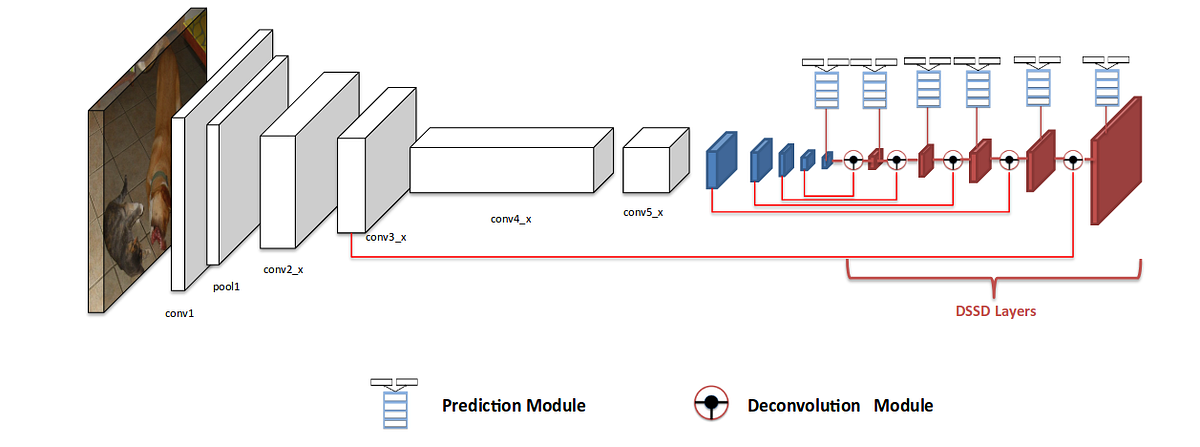
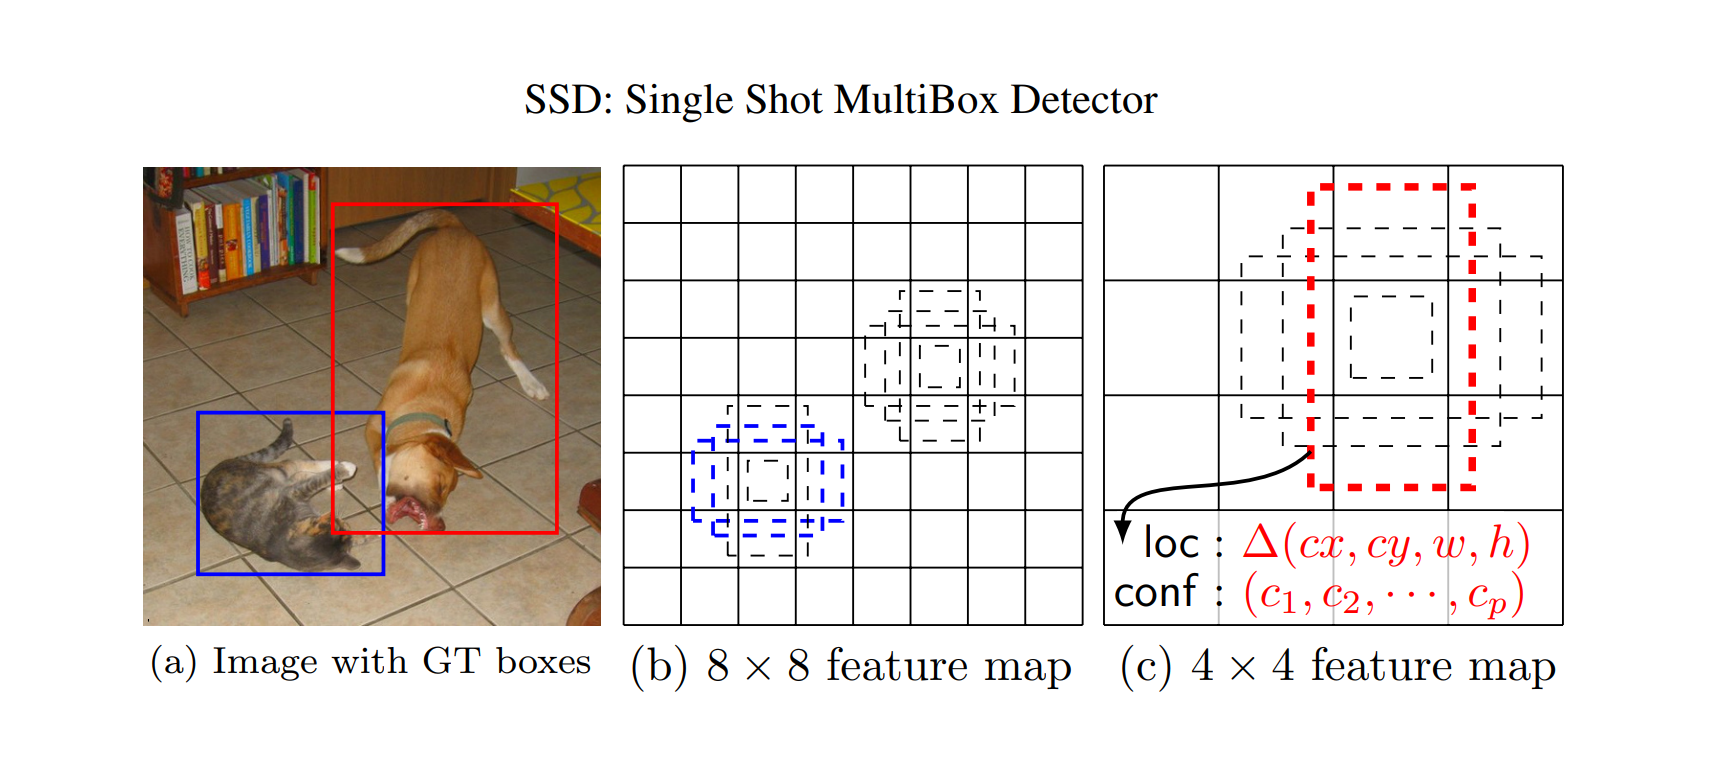
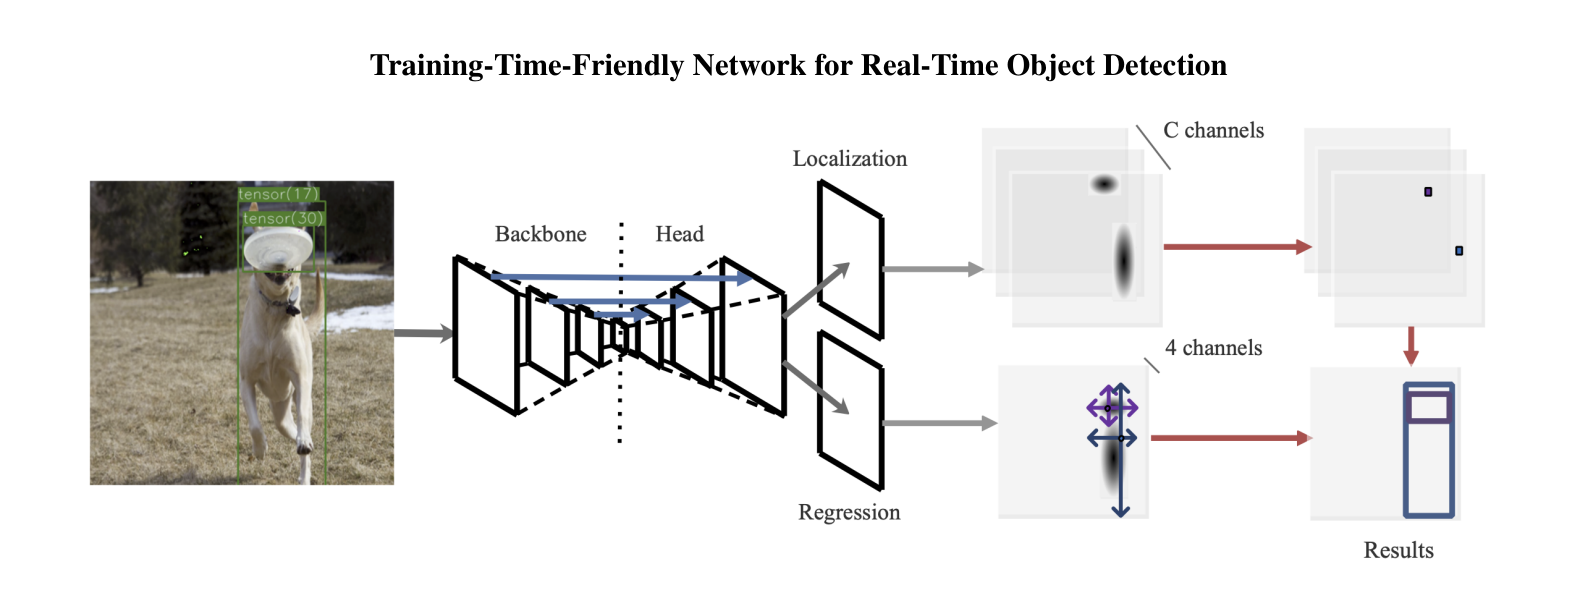

In [11]:
L = tf.keras.layers

# Базовый строительный свёрточный блок модели.
def cbr(x, ch, k, name, dw=False, act=True):
    if dw:
        x = L.DepthwiseConv2D(k, padding="same", use_bias=False, name=name + "_dw")(x)
    else:
        x = L.Conv2D(ch, k, padding="same", use_bias=False, name=name + "_conv")(x)
    x = L.BatchNormalization(name=name + "_bn")(x)
    return L.ReLU(6.0, name=name + "_relu6")(x) if act else x

# Пирамида признаков:
def build_neck(c1, c2, ch):
    # Приводит карту признаков c2 от бэкбоуна 4x4x128 к размерности 4x4x32
    p2 = cbr(c2, ch, 1, "fpn_lat2")
    # Копия карты признаков меньшего разрешения (c2, размер 4x4) увеличиваются вдвое через UpSampling2D
    # и складываются (Add) с более мелкозернистыми признаками (c1, размер 8x8),
    # перед этим карта признаков c1 8x8x64 приводиться к размерности 8x8x32
    p1 = L.Add(name="fpn_add")([cbr(c1, ch, 1, "fpn_lat1"), L.UpSampling2D(2, interpolation="nearest", name="fpn_up")(p2)])
    # Применяются depthwise-separable свёртки (dw=True + pw), чтобы сгладить артефакты после апсемплинга. 
    # На выходе получаются два доработанных уровня: p1 (8x8) и p2 (4x4).
    p1 = cbr(cbr(p1, ch, 3, "fpn_smooth1_dw", dw=True), ch, 1, "fpn_smooth1_pw")
    p2 = cbr(cbr(p2, ch, 3, "fpn_smooth2_dw", dw=True), ch, 1, "fpn_smooth2_pw")
    return p1, p2

# Эта функция создает предсказательный модуль, который ставится после пирамиды признаков:
def head(x, out_ch, name, bias=0.0, relu_out=False):
    # Глубинная свёртка (dw=True с размером ядра 3x3) для извлечения локальных признаков.
    x = cbr(x, 0, 3, name + "_tower", dw=True)
    # Точечная свёртка (1x1 Conv2D) проецирует признаки в нужное количество выходных каналов (out_ch), 
    # определяемое задачей (классы, координаты рамок или тепловые карты).
    x = L.Conv2D(out_ch, 1, padding="same", bias_initializer=tf.keras.initializers.Constant(bias), name=name + "_out")(x)
    return L.ReLU(name=name + "_relu")(x) if relu_out else x

# Функция собирает конечную модель Keras в зависимости от выбранной архитектуры:
def build_detector(arch, backbone, cfg):
    # Количество каналов в промежуточных слоях FPN(Feature Pyramid Networks) и «головах» предсказателях сетей.
    ch = cfg["neck_ch"]
    # Cлои из которых берутся карты признаков в backbone.
    c1 = backbone.get_layer(cfg["backbone"]["path_taps"][0]).output
    c2 = backbone.get_layer(cfg["backbone"]["path_taps"][1]).output
    # Получить пирамиду карт признаков.
    p1, p2 = build_neck(c1, c2, ch)

    if arch == "ssd":
        # Узнаем количество рамок на одну ячейку сетки
        A = cfg["ssd"]["anchors_per_cell"]
        # Список для вероятностей классов и коэфицентов смещения рамок на одну ячейку сетки.
        cls_o, box_o = [], []
        # 1) Для каждого из двух уровней пирамиды (p1 и p2) создаются независимые головы для предсказания классов (cls) и смещений рамок (box).
        # 2) Выходы решейпятся (Reshape) в плоские списки анхоров.
        # 3) С помощью Concatenate результаты с уровней 8x8 и 4x4 объединяются в единые тензоры: 
        #    cls_logits формы [B, A, NumClasses + 1] и box_deltas формы [B, A, 4].
        for lvl, p in enumerate((p1, p2)):
            # Предсказываем классы для каждого анхора и меняем форму тензора (Reshape) в плоский список
            cls_o.append(L.Reshape((-1, NC + 1), name=f"cls_rs{lvl}")(head(p, A * (NC + 1), f"cls{lvl}")))
            # Предсказываем смещения рамок (delta boxes) и также преобразуем форму тензора
            box_o.append(L.Reshape((-1, 4), name=f"box_rs{lvl}")(head(p, A * 4, f"box{lvl}")))
        # Объединяем результаты с обоих уровней в единые массивы по оси батча/анхоров
        outs = [L.Concatenate(axis=1, name="cls_logits")(cls_o), L.Concatenate(axis=1, name="box_deltas")(box_o)]

    elif arch == "ttf":
        # TTFNet (безъякорный детектор) использует только первый уровень пирамиды p1 (8x8).
        # Предсказывает два выхода:
        # • (heatmap): тепловые карты центров объектов размером [B, 8, 8, NumClasses].
        # • расстояния от центра до четырех сторон бокса (Left, Top, Right, Bottom) размером [B, 8, 8, 4], 
        #   пропущенные через ReLU, так как расстояния не могут быть отрицательными
        outs = [head(p1, NC, "hm", bias=cfg["ttf"]["hm_bias"]), # Предсказание тепловых карт (heatmap) центров
                head(p1, 4, "ltrb", bias=0.2, relu_out=True)] # Предсказание расстояний до границ бокса (Left, Top, Right, Bottom)
        # Явно задаем линейные активации для итоговых выходов тепловых карт и отступов рамок
        outs = [L.Activation("linear", name="hm_logits")(outs[0]), L.Activation("linear", name="ltrb")(outs[1])]
    else:
        raise ValueError(arch)
    return tf.keras.Model(backbone.input, outs, name=f"det_{arch}")

# Шаг 7. Функции потерь
Данный блок кода реализует статические, векторизованные функции потерь (Loss Functions), выполняющиеся внутри графовых функций tf.function. Модуль содержит математический аппарат для оптимизации обоих детекторов (SSD и TTFNet). Главное преимущество такого подхода — полная векторизация вычислений без медленных Python-циклов по батчу, что обеспечивает высокую скорость обучения как на GPU, так и при подготовке моделей к развертыванию.

In [12]:
# Вычисление Generalized Intersection over Union (GIoU) для рамки предсказания и реального бокса.
def giou_tf(a, b, eps=1e-7):
    """a,b: [...,4] xyxy → GIoU [...]."""
    iw = tf.maximum(tf.minimum(a[..., 2], b[..., 2]) - tf.maximum(a[..., 0], b[..., 0]), 0.0)
    ih = tf.maximum(tf.minimum(a[..., 3], b[..., 3]) - tf.maximum(a[..., 1], b[..., 1]), 0.0)
    inter = iw * ih
    aa = tf.maximum(a[..., 2] - a[..., 0], 0.0) * tf.maximum(a[..., 3] - a[..., 1], 0.0)
    ab = tf.maximum(b[..., 2] - b[..., 0], 0.0) * tf.maximum(b[..., 3] - b[..., 1], 0.0)
    union = aa + ab - inter + eps
    cw = tf.maximum(a[..., 2], b[..., 2]) - tf.minimum(a[..., 0], b[..., 0])
    ch = tf.maximum(a[..., 3], b[..., 3]) - tf.minimum(a[..., 1], b[..., 1])
    carea = cw * ch + eps
    return inter / union - (carea - union) / carea

# Превращает предсказанные нейросетью дельты (d) обратно в абсолютные координаты xyxy, 
# опираясь на опорные рамки (anc) и коэффициенты масштабирования (var).
def decode_tf(d, anc, var):
    cx = anc[..., 0] + d[..., 0] * var[0] * anc[..., 2]; cy = anc[..., 1] + d[..., 1] * var[1] * anc[..., 3]
    w = anc[..., 2] * tf.exp(tf.clip_by_value(d[..., 2] * var[2], -DELTA_CLIP, DELTA_CLIP))
    h = anc[..., 3] * tf.exp(tf.clip_by_value(d[..., 3] * var[3], -DELTA_CLIP, DELTA_CLIP))
    return tf.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)
    
# Фабрика функций make_loss возвращает готовый объект loss_fn, который на каждом шаге обучения принимает предсказания модели 
# и целевые тензоры, возвращая словарь с детализированными потерями (total, cls, l1, giou) для мониторинга процесса оптимизации.
def make_loss(arch, cfg):
    if arch == "ssd":
        # SSD использует комбинированный Loss, состоящий из трех частей: классификация, сглаженная L1-регрессия и GIoU-регрессия.
        c = cfg["ssd"]; var = tuple(c["variances"]); anc = tf.constant(ANC_CXCYWH)
        def loss_fn(preds, t):
            logits, deltas = preds
            pos = t["pos"]
            cls_t = t["cls"]
            A = tf.cast(tf.shape(pos)[1], tf.float32); npos_i = tf.reduce_sum(pos, 1)           # [B]
            N = tf.maximum(tf.reduce_sum(npos_i), 1.0)
            # Классификация и Hard Negative Mining (OHNM)
            # На изображении всегда гораздо больше фона, чем полезных объектов. Если учить модель на всем фоне, 
            # она быстро начнет предсказывать только фон. Online Hard Negative Mining (OHNM): Код находит фоновые анхоры, 
            # на которых модель ошибается сильнее всего («трудные негативы»), и берет из них строго ограниченное количество 
            # (в пропорции 3 негатива на 1 позитив, но не менее min_neg). Остальной фоновый мусор отбрасывается.
            # Обе ошибки считаются только для позитивных анхоров (* pos) и нормируются на общее количество позитивных объектов (/ N).
            ce = tf.nn.sparse_softmax_cross_entropy_with_logits(labels=cls_t, logits=logits)    # [B,A]
            neg_ce = tf.where(pos > 0.5, -1e9, ce)
            rank = tf.argsort(tf.argsort(neg_ce, axis=1, direction="DESCENDING"), axis=1)       # ранг по убыванию loss
            n_neg = tf.clip_by_value(c["neg_pos_ratio"] * npos_i, c["min_neg"], A - npos_i)     # [B]
            neg_mask = tf.cast(rank < tf.cast(n_neg[:, None], rank.dtype), tf.float32) * (1.0 - pos)
            l_cls = tf.reduce_sum(ce * (pos + neg_mask)) / N
            # Локализация (L1 + GIoU)
            # Smooth-L1 Loss (sl1): Стандартная устойчивая к выбросам функция потерь для регрессии координат рамок.
            # GIoU Loss (l_giou): Штраф за неправильную форму и положение рамки.
            diff = deltas - t["loc"]
            sl1 = tf.where(tf.abs(diff) < 1.0, 0.5 * tf.square(diff), tf.abs(diff) - 0.5)           # smooth-L1, beta=1
            l_l1 = tf.reduce_sum(tf.reduce_sum(sl1, -1) * pos) / N
            pred_box = decode_tf(deltas, anc[None], var)
            l_giou = tf.reduce_sum((1.0 - giou_tf(pred_box, t["gtbox"])) * pos) / N
            total = c["w_cls"] * l_cls + c["w_l1"] * l_l1 + c["w_giou"] * l_giou
            return dict(total=total, cls=l_cls, l1=l_l1, giou=l_giou)
        return loss_fn
    
    # TTFNet - безъякорный детектор, поэтому его функция потерь устроена совершенно иначе (на основе тепловых карт и предсказания расстояний).
    c = cfg["ttf"]; H, W = FEAT_SHAPES[0]
    gy, gx = tf.meshgrid((tf.range(H, dtype=tf.float32) + 0.5) / H, (tf.range(W, dtype=tf.float32) + 0.5) / W, indexing="ij")
    def loss_fn(preds, t):
        hm_logit, ltrb = preds; hm_t = t["hm"]; wgt = t["wgt"]
        # Гауссов Focal Loss для тепловых карт
        # Модифицированный Focal Loss (из CornerNet): Поскольку в центрах объектов значение тепловой карты равно 1.0, 
        # а в окрестности центра оно плавно падает по закону Гаусса (мягкие метки от 0 до 1), стандартная кросс-энтропия не подходит. 
        # Эта формула наказывает модель за неверное предсказание пиков центров объектов, делая больший акцент на сложных для детектирования точках.
        p = tf.clip_by_value(tf.sigmoid(hm_logit), 1e-4, 1.0 - 1e-4); pos = tf.cast(tf.equal(hm_t, 1.0), tf.float32)
        n_obj = tf.maximum(tf.reduce_sum(pos), 1.0)
        pos_l = -tf.math.log(p) * tf.pow(1.0 - p, 2.0) * pos
        neg_l = -tf.math.log(1.0 - p) * tf.pow(p, 2.0) * tf.pow(1.0 - hm_t, 4.0) * (1.0 - pos)
        l_hm = (tf.reduce_sum(pos_l) + tf.reduce_sum(neg_l)) / n_obj
        # Регрессия расстояний (ltrb через GIoU)
        # Сеть предсказывает расстояния от каждой точки сетки до четырех сторон бокса (Left, Top, Right, Bottom).
        # Эти отступы переводятся в координаты рамок функцией to_box, после чего к ним применяется GIoU Loss, 
        # взвешенный коэффициентами гауссианы (wgt), чтобы центральные точки объекта имели больший вес, чем периферийные.
        def to_box(r): return tf.stack([gx - r[..., 0], gy - r[..., 1], gx + r[..., 2], gy + r[..., 3]], -1)
        l_giou = tf.reduce_sum((1.0 - giou_tf(to_box(ltrb), to_box(t["reg"]))) * wgt) / tf.maximum(tf.reduce_sum(wgt), 1.0)
        total = c["w_hm"] * l_hm + c["w_giou"] * l_giou
        return dict(total=total, cls=l_hm, l1=tf.zeros(()), giou=l_giou)
    return loss_fn

# Шаг 8. Обучение
Данный блок кода реализует главный управляющий модуль обучения — класс Trainer, который инкапсулирует весь жизненный цикл моделей (SSD и TTFNet). Модуль объединяет графовые вычисления TensorFlow (tf.function), раздельные оптимизаторы AdamW для бэкбона и головы, расчет экспоненциального скользящего среднего весов (EMA), а также полноценный цикл валидации с вычислением метрик детекции в реальном времени и сохранением лучших чекпоинтов.

In [13]:
# Преобразует тензоры с выходами модели (outs), которые находятся в памяти TensorFlow/GPU, в стандартные массивы NumPy (numpy.ndarray).
def raw_to_np(arch, outs):
    return [o.numpy() if hasattr(o, "numpy") else np.asarray(o) for o in outs]

# Пакетно декодирует сырые выходы нейросети (логиты классов и дельты рамок для SSD или тепловые карты и отступы ltrb для TTFNet) 
# в итоговые понятные координаты (xyxy), уверенности (scores) и метки классов (labels), применяя фильтрацию по порогу (conf_thr) и 
# подавление неудачных рамок через NMS.
def decode_batch(arch, outs, post=CFG["post"], conf_thr=None):
    o = raw_to_np(arch, outs); thr = post["conf_thr"] if conf_thr is None else conf_thr
    if arch == "ssd":
        return decode_ssd_np(o[0], o[1], ANC_CXCYWH, SSD_C["variances"], thr, post["nms_iou"], post["pre_nms_topk"], post["max_det"])
    return decode_ttf_np(o[0], o[1], thr, post["nms_iou"], post["pre_nms_topk"], post["max_det"])

# Главный управляющий класс, который инкапсулирует всю логику обучения: собирает модель, настраивает оптимизаторы 
# с разделением на backbone и голову, выполняет шаги градиентного спуска (train_step), считает валидационные метрики, 
# следит за EMA-весами и сохраняет лучший чекпоинт по эпохам.
class Trainer:
    def __init__(self, arch, cfg, backbone_model):
        self.arch, self.cfg = arch, cfg; self.tc = cfg["train"]
        self.model = build_detector(arch, backbone_model, cfg); self.loss_fn = make_loss(arch, cfg)
        self.tfn = ssd_target_fn if arch == "ssd" else ttf_target_fn
        bb_names = {l.name for l in backbone_model.layers}
        self.bb_vars = [v for l in self.model.layers if l.name in bb_names for v in l.trainable_variables]
        bb_ids = {id(v) for v in self.bb_vars}
        self.hd_vars = [v for v in self.model.trainable_variables if id(v) not in bb_ids]
        self.train_batcher = Batcher(train_data, self.tfn, self.tc["batch_size"], True, cfg["aug"], self.tc["seed"])
        self.val_batcher = Batcher(val_data, self.tfn, self.tc["batch_size"], False)
        steps = len(self.train_batcher) * self.tc["epochs"]; wu = len(self.train_batcher) * self.tc["warmup_epochs"]
        self.sched_bb = WarmupCosine(self.tc["lr_backbone"], steps, wu, self.tc["lr_backbone"] * self.tc["min_lr_ratio"])
        self.sched_hd = WarmupCosine(self.tc["lr_head"], steps, wu, self.tc["lr_head"] * self.tc["min_lr_ratio"])
        mk = lambda sch: tf.keras.optimizers.AdamW(learning_rate=sch, weight_decay=self.tc["weight_decay"])
        self.opt_bb, self.opt_hd = mk(self.sched_bb), mk(self.sched_hd)
        for o in (self.opt_bb, self.opt_hd):
            try: o.exclude_from_weight_decay(var_names=["bn", "bias", "beta", "gamma"])
            except Exception: pass
        self.ema = [tf.Variable(w, trainable=False) for w in self.model.weights]; self.ema_steps = tf.Variable(0.0, trainable=False)
        self.history = {k: [] for k in ("loss", "val_loss", "val_mAP50", "val_mAP", "val_f1", "val_top1", "cls", "giou", "lr")}
        self.best = dict(score=-1, loss=1e9, epoch=-1)
        self.ckpt = str(OUT_DIR / f"{arch}_best.h5")

        @tf.function(reduce_retracing=True)
        def train_step(x, t):
            with tf.GradientTape() as tape:
                preds = self.model(x, training=True); ls = self.loss_fn(preds, t)
            allv = self.bb_vars + self.hd_vars; g = tape.gradient(ls["total"], allv)
            g, _ = tf.clip_by_global_norm(g, self.tc["clip_norm"])
            nb = len(self.bb_vars)
            self.opt_bb.apply_gradients(zip(g[:nb], self.bb_vars)); self.opt_hd.apply_gradients(zip(g[nb:], self.hd_vars))
            self.ema_steps.assign_add(1.0); d = tf.minimum(self.tc["ema_decay"], (1.0 + self.ema_steps) / (10.0 + self.ema_steps))
            for e, w in zip(self.ema, self.model.weights): e.assign(d * e + (1.0 - d) * w)
            return ls
        self.train_step = train_step

        @tf.function(reduce_retracing=True)
        def eval_step(x, t):
            preds = self.model(x, training=False); return preds, self.loss_fn(preds, t)
        self.eval_step = eval_step

    # --- EMA swap ---
    # Временно подменяет текущие рабочие веса модели на сглаженные веса экспоненциального скользящего среднего (EMA). 
    # Это делается перед валидацией, чтобы замерять метрики по более стабильным и точным весам.
    def _swap_in_ema(self):
        self._backup = self.model.get_weights(); self.model.set_weights([e.numpy() for e in self.ema])
    # Возвращает исходные (рабочие) веса модели на место сразу после завершения валидации, чтобы процесс обучения на 
    # следующем шаге продолжился с ними, не нарушая состояние оптимизатора.
    def _swap_out(self):
        self.model.set_weights(self._backup)

    # Функция оценки модели evaluate
    # Проходит по всему валидационному датасету.
    # Собирает сырые предсказания модели и декодирует их в финальные ограничивающие рамки с помощью decode_batch.
    # Вызывает функцию evaluate_detections, которая считает метрики детекции (mAP@50, mAP@50:95, Precision, Recall, F1 и др.).
    def evaluate(self, batcher, conf_thr=None):
        dets, gtb, gtl, losses = [], [], [], []
        for x, t, gb, gl in batcher:
            preds, ls = self.eval_step(x, t); losses.append(float(ls["total"]) * len(x))
            dets += decode_batch(self.arch, preds, conf_thr=conf_thr); gtb += gb; gtl += gl
        m = evaluate_detections(dets, gtb, gtl, NC, self.cfg["post"]["op_thr"]); m["loss"] = sum(losses) / max(len(gtb), 1)
        return m, dets

    # Основной цикл обучения
    def fit(self, verbose=True):
        tc = self.tc; bad = 0; t0 = time.time()
        for ep in range(tc["epochs"]):
            run = {"total": [], "cls": [], "giou": []}
            for x, t, _, _ in tqdm(self.train_batcher, desc=f"[{self.arch}] ep {ep + 1}/{tc['epochs']}", leave=False):
                ls = self.train_step(x, t)
                for k in run: run[k].append(float(ls[k]))
                if not np.isfinite(run["total"][-1]): print("NaN loss — остановка"); return self.history
            self._swap_in_ema(); m, _ = self.evaluate(self.val_batcher); score = m["mAP50"]
            improved = score > self.best["score"] + 1e-4 or (abs(score - self.best["score"]) <= 1e-4 and m["loss"] < self.best["loss"])
            if improved:
                self.best = dict(score=score, loss=m["loss"], epoch=ep); self.model.save_weights(self.ckpt); bad = 0
            else:
                bad += 1
            self._swap_out()
            h = self.history; h["loss"].append(float(np.mean(run["total"]))); h["val_loss"].append(m["loss"]); h["val_mAP50"].append(m["mAP50"])
            h["val_mAP"].append(m["mAP"]); h["val_f1"].append(m["f1"]); h["val_top1"].append(m["top1_acc"])
            h["cls"].append(float(np.mean(run["cls"]))); h["giou"].append(float(np.mean(run["giou"])))
            h["lr"].append(float(self.sched_hd(self.opt_hd.iterations)))
            if verbose and (ep % 5 == 0 or improved):
                print(f"[{self.arch}] ep {ep + 1:3d} | loss {h['loss'][-1]:.3f} val {m['loss']:.3f} | "
                      f"val mAP50 {m['mAP50']:.3f} mAP {m['mAP']:.3f} F1 {m['f1']:.3f} top1 {m['top1_acc']:.3f}"
                      f"{'  *best*' if improved else ''} ({time.time() - t0:.0f}s)")
            if bad >= tc["patience"]:
                print(f"[{self.arch}] ранняя остановка на эпохе {ep + 1}; лучшая эпоха {self.best['epoch'] + 1}, val mAP50 {self.best['score']:.3f}"); break
        self.model.load_weights(self.ckpt)          # лучшие (EMA) веса
        return self.history

### Запуск обучения обоих детекторов

In [14]:
set_seed(CFG["train"]["seed"])
trainers = {}
for arch in CFG["archs"]:
    # у каждого детектора свой экземпляр backbone (свои веса), чтобы обучения не влияли друг на друга
    bb = load_backbone(CFG["paths"]["backbone"], CFG["backbone"]["pretrained"])
    tr = Trainer(arch, CFG, bb)
    n_par = tr.model.count_params(); print(f"\n=== {arch}: параметров {n_par:,} (~{n_par/1024:.1f} КБ в int8), позитивов/кадр и т.д. см. loss ===")
    tr.fit(); trainers[arch] = tr

summary = {a: (t.best["score"], t.best["epoch"] + 1) for a, t in trainers.items()}
print("\nИтог val mAP@0.5:", {a: f"{s:.3f} (эпоха {e})" for a, (s, e) in summary.items()})
BEST_ARCH = max(summary, key=lambda a: summary[a][0]); print("Выбран:", BEST_ARCH)


=== ssd: параметров 26,648 (~26.0 КБ в int8), позитивов/кадр и т.д. см. loss ===


[ssd] ep 1/150:   0%|          | 0/71 [00:00<?, ?it/s]

[ssd] ep   1 | loss 12.335 val 165.555 | val mAP50 0.009 mAP 0.002 F1 0.012 top1 0.475  *best* (8s)


[ssd] ep 2/150:   0%|          | 0/71 [00:00<?, ?it/s]

[ssd] ep   2 | loss 7.684 val 135.828 | val mAP50 0.197 mAP 0.052 F1 0.087 top1 0.530  *best* (11s)


[ssd] ep 3/150:   0%|          | 0/71 [00:00<?, ?it/s]

... (414 outputs left out)

[ttf] ep 148/150:   0%|          | 0/71 [00:00<?, ?it/s]

[ttf] ep 149/150:   0%|          | 0/71 [00:00<?, ?it/s]

[ttf] ep 150/150:   0%|          | 0/71 [00:00<?, ?it/s]


Итог val mAP@0.5: {'ssd': '0.945 (эпоха 132)', 'ttf': '0.917 (эпоха 147)'}
Выбран: ssd


### Кривые обучения
Cтроим реальные метрики детекции на валидации.

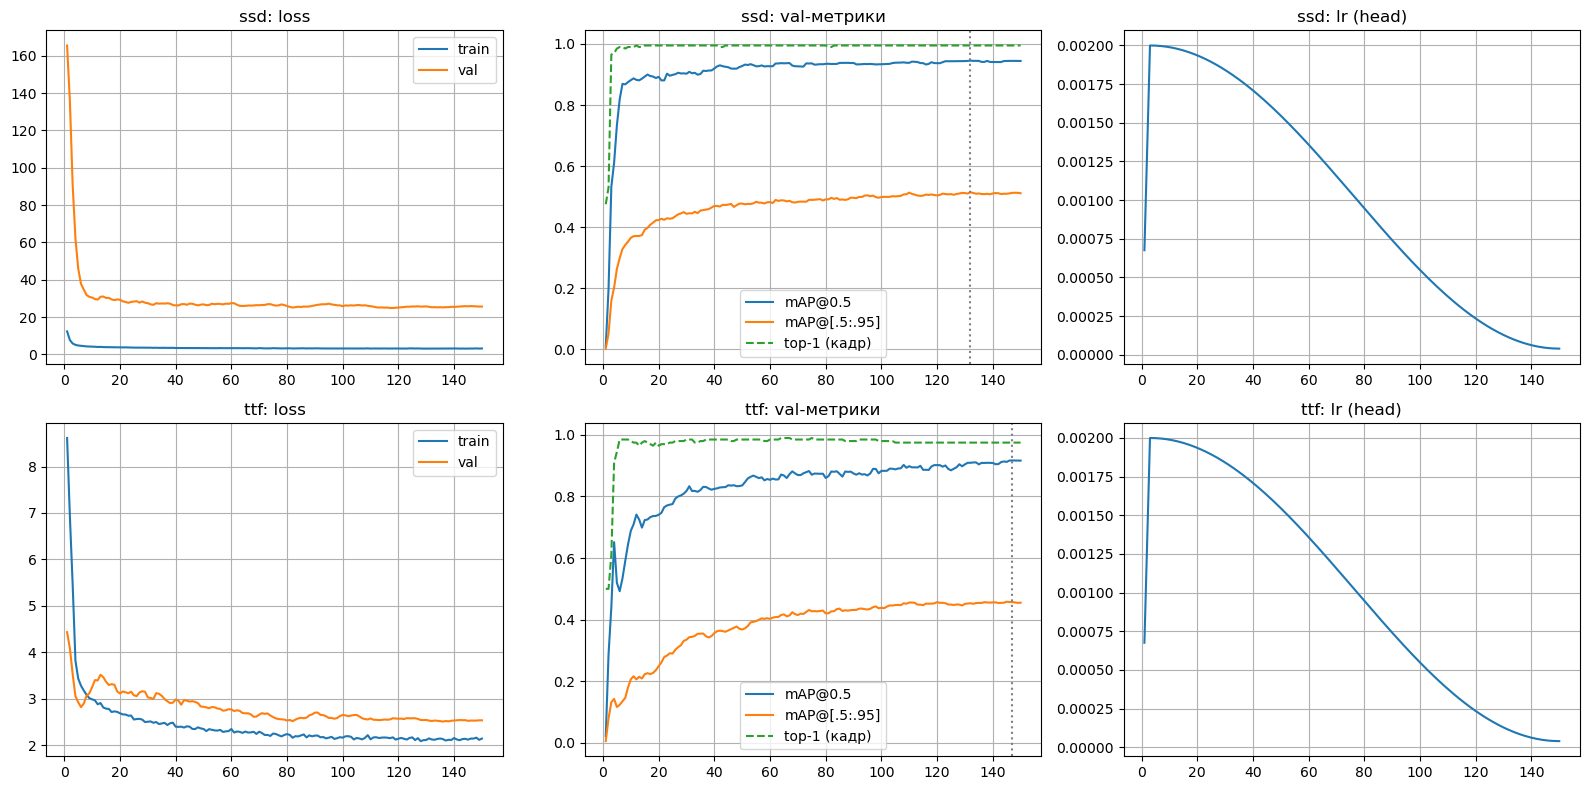

In [15]:
fig, ax = plt.subplots(len(trainers), 3, figsize=(16, 4 * len(trainers)), squeeze=False)
for r, (a, tr) in enumerate(trainers.items()):
    h = tr.history; ep = np.arange(1, len(h["loss"]) + 1)
    ax[r, 0].plot(ep, h["loss"], label="train"); ax[r, 0].plot(ep, h["val_loss"], label="val"); ax[r, 0].set_title(f"{a}: loss"); ax[r, 0].legend(); ax[r, 0].grid(True)
    ax[r, 1].plot(ep, h["val_mAP50"], label="mAP@0.5"); ax[r, 1].plot(ep, h["val_mAP"], label="mAP@[.5:.95]"); ax[r, 1].plot(ep, h["val_top1"], label="top-1 (кадр)", ls="--")
    ax[r, 1].axvline(tr.best["epoch"] + 1, color="gray", ls=":"); ax[r, 1].set_title(f"{a}: val-метрики"); ax[r, 1].legend(); ax[r, 1].grid(True)
    ax[r, 2].plot(ep, h["lr"]); ax[r, 2].set_title(f"{a}: lr (head)"); ax[r, 2].grid(True)
plt.tight_layout(); plt.show()

# Шаг 9. Оценка float-моделей (val / test), рабочая точка
Сначала сравниваем детекторы на валидации и выбираем порог уверенности по максимуму F1 (**на val, не на test**). Затем один раз смотрим test.

[ssd] VAL  (float): mAP50 0.945 | mAP50:95 0.514 | P 0.803 R 0.954 F1 0.872 | mIoU 0.773 | top1 0.995 (+loc 0.975) | miss 0.022 | bgFP 0.250
[ttf] VAL  (float): mAP50 0.917 | mAP50:95 0.457 | P 0.739 R 0.935 F1 0.825 | mIoU 0.760 | top1 0.975 (+loc 0.940) | miss 0.013 | bgFP 0.330


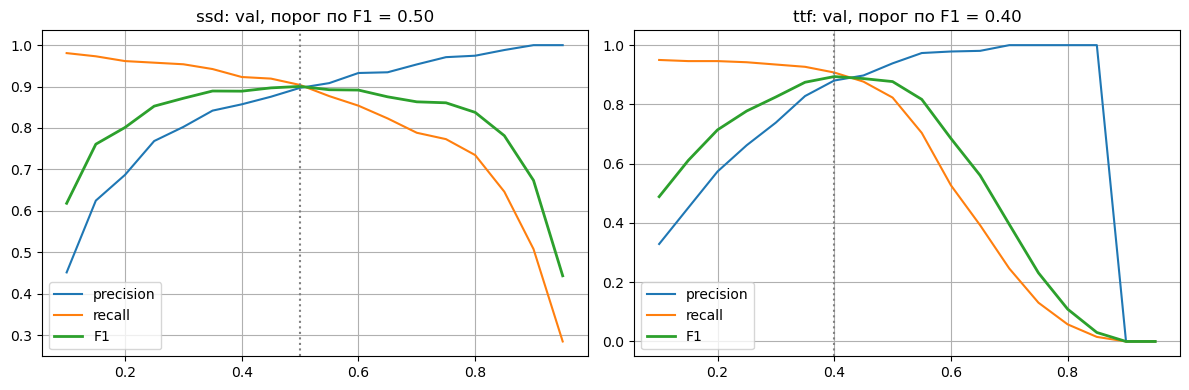


--- TEST (float) ---
[ssd] TEST (float): mAP50 0.926 | mAP50:95 0.509 | P 0.774 R 0.923 F1 0.842 | mIoU 0.776 | top1 0.955 (+loc 0.925) | miss 0.026 | bgFP 0.250
      AP50 по классам: {'matrjona': 0.934, 'mouse': 0.917}
[ttf] TEST (float): mAP50 0.909 | mAP50:95 0.465 | P 0.742 R 0.931 F1 0.826 | mIoU 0.763 | top1 0.970 (+loc 0.910) | miss 0.013 | bgFP 0.260
      AP50 по классам: {'matrjona': 0.908, 'mouse': 0.911}


In [16]:
def sweep_threshold(dets, gtb, gtl, grid=np.round(np.arange(0.1, 0.96, 0.05), 2)):
    rows = []
    for t in grid:
        m = evaluate_detections(dets, gtb, gtl, NC, float(t)); rows.append((t, m["precision"], m["recall"], m["f1"], m["top1_acc"]))
    return np.array(rows)

fig, ax = plt.subplots(1, len(trainers), figsize=(6 * len(trainers), 4), squeeze=False)
OP_THR = {}
for k, (a, tr) in enumerate(trainers.items()):
    m, dets = tr.evaluate(tr.val_batcher)
    gtb = [b for _, _, gb, _ in Batcher(val_data, tr.tfn, 32, False) for b in gb]; gtl = [l for _, _, _, gl in Batcher(val_data, tr.tfn, 32, False) for l in gl]
    sw = sweep_threshold(dets, gtb, gtl); OP_THR[a] = float(sw[np.argmax(sw[:, 3]), 0])
    ax[0, k].plot(sw[:, 0], sw[:, 1], label="precision"); ax[0, k].plot(sw[:, 0], sw[:, 2], label="recall"); ax[0, k].plot(sw[:, 0], sw[:, 3], label="F1", lw=2)
    ax[0, k].axvline(OP_THR[a], color="gray", ls=":"); ax[0, k].set_title(f"{a}: val, порог по F1 = {OP_THR[a]:.2f}"); ax[0, k].legend(); ax[0, k].grid(True)
    print(f"[{a}] VAL  (float): {fmt_metrics(m)}")
plt.tight_layout(); plt.show()

print("\n--- TEST (float) ---")
for a, tr in trainers.items():
    tb = Batcher(test_data, tr.tfn, 32, False); m, _ = tr.evaluate(tb)
    print(f"[{a}] TEST (float): {fmt_metrics(m)}\n      AP50 по классам: { {k: round(v, 3) for k, v in m['AP50_per_class'].items()} }")

### Визуализация предсказаний лучшего детектора
Зелёный рамки - истинные, красные — предсказаные. Нижний ряд — только ошибки (промах / неверный класс / IoU < 0.5).

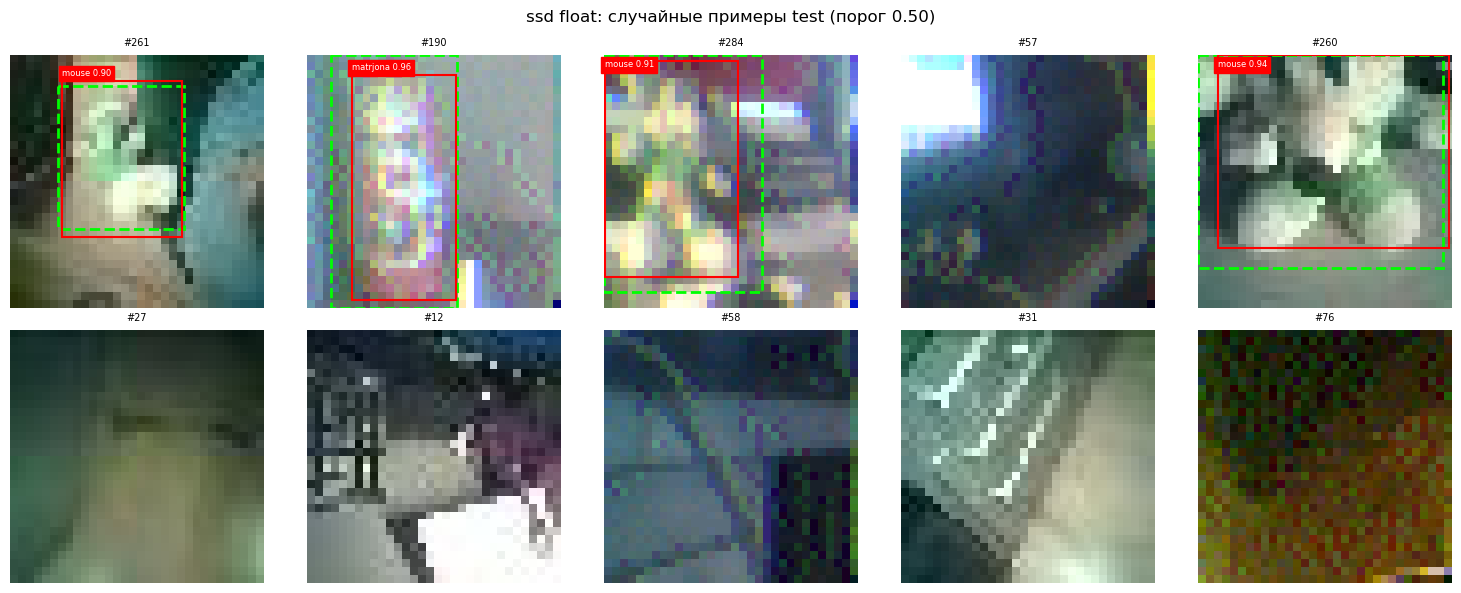

Ошибочных кадров на test: 56 из 330


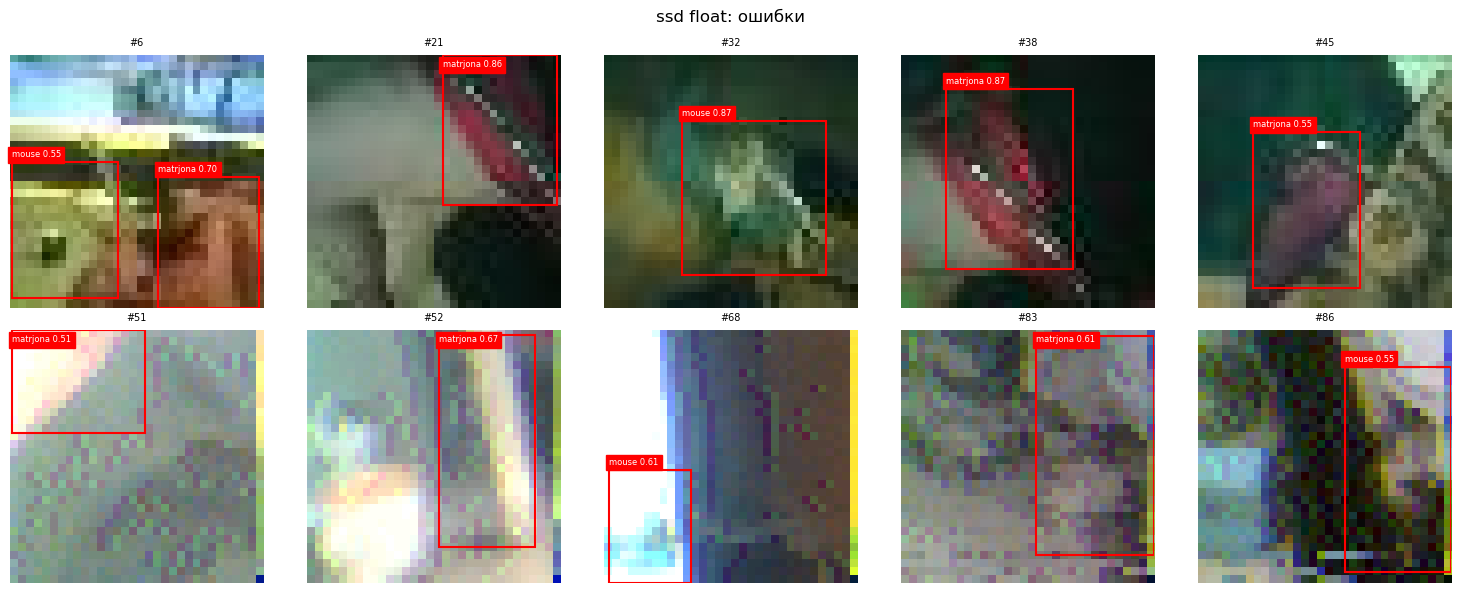

In [17]:
def draw(ax, img, gt_b, gt_l, det, title=""):
    ax.imshow(img, extent=(0, 1, 1, 0), interpolation="nearest"); ax.axis("off"); ax.set_title(title, fontsize=7)
    for b in gt_b: ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=2, ls="--"))
    for b, s, l in zip(det["boxes"], det["scores"], det["labels"]):
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=1.5))
        ax.text(b[0], max(b[1] - 0.02, 0.05), f"{FG[l]} {s:.2f}", color="white", backgroundcolor="red", fontsize=6)

def predict_float(tr, data, conf_thr=None):
    out = []
    for s in range(0, len(data["images"]), 64):
        x = data["images"][s:s + 64].astype(np.float32) / 255.0; out += decode_batch(tr.arch, tr.model(x, training=False), conf_thr=conf_thr)
    return out

def is_error(d, gb, gl, thr):
    k = d["scores"] >= thr
    if len(gb) == 0: return bool(k.any())
    if not k.any(): return True
    t = int(np.argmax(np.where(k, d["scores"], -1)))
    return not (d["labels"][t] == gl[0] and iou_np(d["boxes"][t][None], gb)[0].max() >= 0.5)

def show_grid(data, dets, idxs, thr, title):
    cols = 5; rows = int(math.ceil(len(idxs) / cols)); fig, ax = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)
    for a_ in ax.ravel(): a_.axis("off")
    for a_, i in zip(ax.ravel(), idxs):
        d = dets[i]; k = d["scores"] >= thr
        draw(a_, data["images"][i], data["boxes"][i], data["labels"][i], dict(boxes=d["boxes"][k], scores=d["scores"][k], labels=d["labels"][k]),
             f"#{i}")
    fig.suptitle(title); plt.tight_layout(); plt.show()

_tr = trainers[BEST_ARCH]; _thr = OP_THR[BEST_ARCH]; _dets = predict_float(_tr, test_data)
rng_v = np.random.default_rng(3)
show_grid(test_data, _dets, rng_v.choice(len(test_data["images"]), 10, replace=False), _thr, f"{BEST_ARCH} float: случайные примеры test (порог {_thr:.2f})")
_err = [i for i in range(len(test_data["images"])) if is_error(_dets[i], test_data["boxes"][i], test_data["labels"][i], _thr)]
print(f"Ошибочных кадров на test: {len(_err)} из {len(test_data['images'])}")
if _err: show_grid(test_data, _dets, _err[:10], _thr, f"{BEST_ARCH} float: ошибки")

# Шаг 10. Квантование в INT8 (PTQ)
Данный блок кода реализует финальный этап пайплайна — квантование обученных моделей в 8-битный целочисленный формат (INT8) с использованием Post-Training Quantization (PTQ), а также создание программной обёртки для их оценки (TFLiteDetector). Квантование в INT8 критически важно для развертывания нейросетей на микроконтроллерах и встраиваемых платах (например, на базе ESP32 / STM32), так как оно уменьшает размер модели примерно в 4 раза и в разы ускоряет вычисления за счет использования целочисленной арифметики.

In [18]:
# Функция создает калибровочную выборку, которая необходима квантователю, 
# чтобы узнать диапазон значений (минимальные и максимальные активации) в слоях нейросети.
def make_representative(n, seed=0):
    rng = np.random.default_rng(seed); imgs = train_data["images"]; idx = rng.permutation(len(imgs))
    xs = [imgs[i].astype(np.float32) / 255.0 for i in idx[:n]]
    photo_only = dict(CFG["aug"], p_flip=0.0, p_affine=0.0, p_erase=0.0, p_mosaic=0.0, p_photo=1.0)
    for i in idx[: n // 3]:
        x, _, _ = augment_one(imgs[i].astype(np.float32) / 255.0, np.zeros((0, 4), np.float32), np.zeros(0, np.int32), rng, photo_only); xs.append(x)
    return np.stack(xs).astype(np.float32)

# Функция конвертирует стандартную модель Keras в файл TensorFlow Lite (.tflite) с полным квантованием в INT8.
def convert_int8(keras_model, calib):
    inp = tf.keras.Input(shape=keras_model.input_shape[1:], batch_size=1)      # статический batch = 1
    static = tf.keras.Model(inp, keras_model(inp))
    conv = tf.lite.TFLiteConverter.from_keras_model(static)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = lambda: ([c[None, ...]] for c in calib)
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
    return conv.convert()

# Класс работает как удобный интерфейс (обёртка) для запуска квантованной TFLite-модели и проверки её работы прямо в Python.
class TFLiteDetector:
    """Обёртка над tf.lite.Interpreter: квантует вход, деквантует выходы, возвращает сырые тензоры в порядке Keras-модели."""
    def __init__(self, tflite_bytes, arch, keras_model, probe):
        try:
            self.it = tf.lite.Interpreter(model_content=tflite_bytes, experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)
        except Exception:
            self.it = tf.lite.Interpreter(model_content=tflite_bytes)
        self.it.allocate_tensors(); self.arch = arch
        self.inp = self.it.get_input_details()[0]; self.outs = self.it.get_output_details()
        self.in_scale, self.in_zp = self.inp["quantization"]
        exp_shapes = [tuple(s[1:]) for s in keras_model.output_shape]; ref = [o.numpy() for o in keras_model(probe, training=False)]
        raw = self._run_all(probe[0]); self.order = []
        for e, shp in enumerate(exp_shapes):
            cand = [j for j, o in enumerate(self.outs) if tuple(o["shape"][1:]) == shp and j not in self.order]
            if len(cand) > 1: cand = [min(cand, key=lambda j: float(np.mean((raw[j] - ref[e][0]) ** 2)))]


            # # ----- проверка --------
            print("\nАрхитектура:", arch)
            print("Keras outputs:", keras_model.output_shape)
            
            for j, o in enumerate(self.outs):
                print(
                    f"TFLite output {j}:",
                    o["name"],
                    "shape =", o["shape"],
                    "signature =", o["shape_signature"]
                )
            
            print("Ожидаемые формы:", exp_shapes)
            # # ----- проверка --------
            assert len(cand) == 1, f"не удалось сопоставить выход {e} {shp}"; self.order.append(cand[0])
    # Подготавливает одно изображение: переводит входящий float в формат int8 по формуле квантования (с учетом scale и zero-point).
    def _run_all(self, x):
        q = np.clip(np.round(x[None] / self.in_scale + self.in_zp), -128, 127).astype(np.int8)
        self.it.set_tensor(self.inp["index"], q); self.it.invoke()
        res = []
        for o in self.outs:
            s, z = o["quantization"]; res.append(((self.it.get_tensor(o["index"]).astype(np.float32) - z) * s)[0])
        return res
    # Вызывает _run_all и возвращает выходы модели в том же порядке, в каком их выдавала исходная Keras-модель.
    def raw(self, x):                     # x: [32,32,3] float 0..1 → выходы в порядке keras (без batch)
        r = self._run_all(x); return [r[j] for j in self.order]
    # Принимает список картинок в формате uint8 (обычные пиксели от 0 до 255), 
    # прогоняет их через модель поочерёдно и возвращает готовые пакеты предсказаний.
    def predict(self, images_u8):
        outs = [self.raw(im.astype(np.float32) / 255.0) for im in images_u8]
        return [np.stack([o[k] for o in outs]) for k in range(len(self.order))]

calib = make_representative(CFG["quant"]["calib_samples"]); print("Калибровочная выборка:", calib.shape, "диапазон", calib.min(), calib.max())
tflite_models, tfl_det = {}, {}
for a, tr in trainers.items():
    blob = convert_int8(tr.model, calib); tflite_models[a] = blob
    (OUT_DIR / f"detector_{a}_int8.tflite").write_bytes(blob)
    tfl_det[a] = TFLiteDetector(blob, a, tr.model, calib[:1])
    d = tfl_det[a]
    print(f"[{a}] TFLite INT8: {len(blob) / 1024:.1f} КБ | вход scale={d.in_scale:.6f} zp={d.in_zp} (классификатор: 1/255={1/255:.6f}, -128) | "
          f"выходы TFLite→keras порядок {d.order}: " + ", ".join(f"{o['name'].split('/')[-1]}{tuple(o['shape'][1:])} s={o['quantization'][0]:.4g}" for o in d.outs))

Калибровочная выборка: (400, 32, 32, 3) диапазон 0.0 1.0
INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmp76lfip4_\assets


INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmp76lfip4_\assets
C:\Users\STEPANJUK\.conda\envs\STEP1\lib\site-packages\tensorflow\lite\python\convert.py:887: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(



Архитектура: ssd
Keras outputs: [(None, 320, 3), (None, 320, 4)]
TFLite output 0: StatefulPartitionedCall:0 shape = [  1 320   3] signature = [  1 320   3]
TFLite output 1: StatefulPartitionedCall:1 shape = [  1 320   4] signature = [  1 320   4]
Ожидаемые формы: [(320, 3), (320, 4)]

Архитектура: ssd
Keras outputs: [(None, 320, 3), (None, 320, 4)]
TFLite output 0: StatefulPartitionedCall:0 shape = [  1 320   3] signature = [  1 320   3]
TFLite output 1: StatefulPartitionedCall:1 shape = [  1 320   4] signature = [  1 320   4]
Ожидаемые формы: [(320, 3), (320, 4)]
[ssd] TFLite INT8: 58.8 КБ | вход scale=0.003922 zp=-128 (классификатор: 1/255=0.003922, -128) | выходы TFLite→keras порядок [0, 1]: StatefulPartitionedCall:0(320, 3) s=0.06998, StatefulPartitionedCall:1(320, 4) s=0.03984
INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmpxdfr640g\assets


INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmpxdfr640g\assets
C:\Users\STEPANJUK\.conda\envs\STEP1\lib\site-packages\tensorflow\lite\python\convert.py:887: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(



Архитектура: ttf
Keras outputs: [(None, 8, 8, 2), (None, 8, 8, 4)]
TFLite output 0: StatefulPartitionedCall:1 shape = [1 8 8 4] signature = [1 8 8 4]
TFLite output 1: StatefulPartitionedCall:0 shape = [1 8 8 2] signature = [1 8 8 2]
Ожидаемые формы: [(8, 8, 2), (8, 8, 4)]

Архитектура: ttf
Keras outputs: [(None, 8, 8, 2), (None, 8, 8, 4)]
TFLite output 0: StatefulPartitionedCall:1 shape = [1 8 8 4] signature = [1 8 8 4]
TFLite output 1: StatefulPartitionedCall:0 shape = [1 8 8 2] signature = [1 8 8 2]
Ожидаемые формы: [(8, 8, 2), (8, 8, 4)]
[ttf] TFLite INT8: 45.5 КБ | вход scale=0.003922 zp=-128 (классификатор: 1/255=0.003922, -128) | выходы TFLite→keras порядок [1, 0]: StatefulPartitionedCall:1(8, 8, 4) s=0.002845, StatefulPartitionedCall:0(8, 8, 2) s=0.04593


### Финальная количественная оценка качества квантованных INT8-моделей на валидационной и тестовой выборках. 
Скрипт автоматизирует сравнение метрик исходных (float) и квантованных сетей, а также вычисляет уровень погрешности квантования для каждого из выходных тензоров, что позволяет вовремя выявить возможные «узкие места» (bottlenecks) в динамическом диапазоне активаций.

In [19]:
# Функция предназначена для полной оценки качества квантованной INT8-модели на заданном наборе данных. 
# Она прогоняет изображения через TFLite-модель, расшифровывает результаты и сравнивает их с реальной разметкой.
def eval_int8(a, data, conf_thr=None):
    d = tfl_det[a]; outs = d.predict(data["images"])
    dets = decode_batch(a, outs, conf_thr=conf_thr)
    return evaluate_detections(dets, data["boxes"], data["labels"], NC, CFG["post"]["op_thr"]), dets, outs

rows = []
for a, tr in trainers.items():
    for split, data in (("val", val_data), ("test", test_data)):
        m_f, _ = tr.evaluate(Batcher(data, tr.tfn, 32, False))
        m_q, _, _ = eval_int8(a, data)
        rows.append((a, split, m_f, m_q))
        print(f"[{a}] {split:4s} float: {fmt_metrics(m_f)}\n{' ' * 7}{'':4s}  INT8: {fmt_metrics(m_q)}   Δ mAP50 = {m_q['mAP50'] - m_f['mAP50']:+.3f}")

# Ошибка квантования выходов (float Keras vs INT8) на val: если большая — искать «узкое место» (диапазон выходов)
a = BEST_ARCH
_, _, q_outs = eval_int8(a, val_data)
f_outs = [o.numpy() for o in trainers[a].model(val_data["images"].astype(np.float32) / 255.0, training=False)]
for k, (qo, fo) in enumerate(zip(q_outs, f_outs)):
    err = np.abs(qo - fo); rng_ = fo.max() - fo.min()
    print(f"выход {k} {fo.shape[1:]}: диапазон {fo.min():.2f}..{fo.max():.2f} | |ошибка| mean {err.mean():.4f}, max {err.max():.3f} ({100 * err.max() / max(rng_, 1e-9):.1f} % диапазона)")

[ssd] val  float: mAP50 0.945 | mAP50:95 0.514 | P 0.803 R 0.954 F1 0.872 | mIoU 0.773 | top1 0.995 (+loc 0.975) | miss 0.022 | bgFP 0.250
             INT8: mAP50 0.945 | mAP50:95 0.510 | P 0.793 R 0.958 F1 0.868 | mIoU 0.774 | top1 0.995 (+loc 0.975) | miss 0.017 | bgFP 0.250   Δ mAP50 = -0.000
[ssd] test float: mAP50 0.926 | mAP50:95 0.509 | P 0.774 R 0.923 F1 0.842 | mIoU 0.776 | top1 0.955 (+loc 0.925) | miss 0.026 | bgFP 0.250
             INT8: mAP50 0.928 | mAP50:95 0.510 | P 0.755 R 0.927 F1 0.832 | mIoU 0.776 | top1 0.955 (+loc 0.930) | miss 0.022 | bgFP 0.270   Δ mAP50 = +0.002
[ttf] val  float: mAP50 0.917 | mAP50:95 0.457 | P 0.739 R 0.935 F1 0.825 | mIoU 0.760 | top1 0.975 (+loc 0.940) | miss 0.013 | bgFP 0.330
             INT8: mAP50 0.907 | mAP50:95 0.452 | P 0.722 R 0.931 F1 0.813 | mIoU 0.760 | top1 0.975 (+loc 0.925) | miss 0.013 | bgFP 0.350   Δ mAP50 = -0.010
[ttf] test float: mAP50 0.909 | mAP50:95 0.465 | P 0.742 R 0.931 F1 0.826 | mIoU 0.763 | top1 0.970 (+loc 

### Сравнение на тесте float vs INT8
Порог выбран по F1 на val для float-модели; INT8 оценивается с тем же порогом.

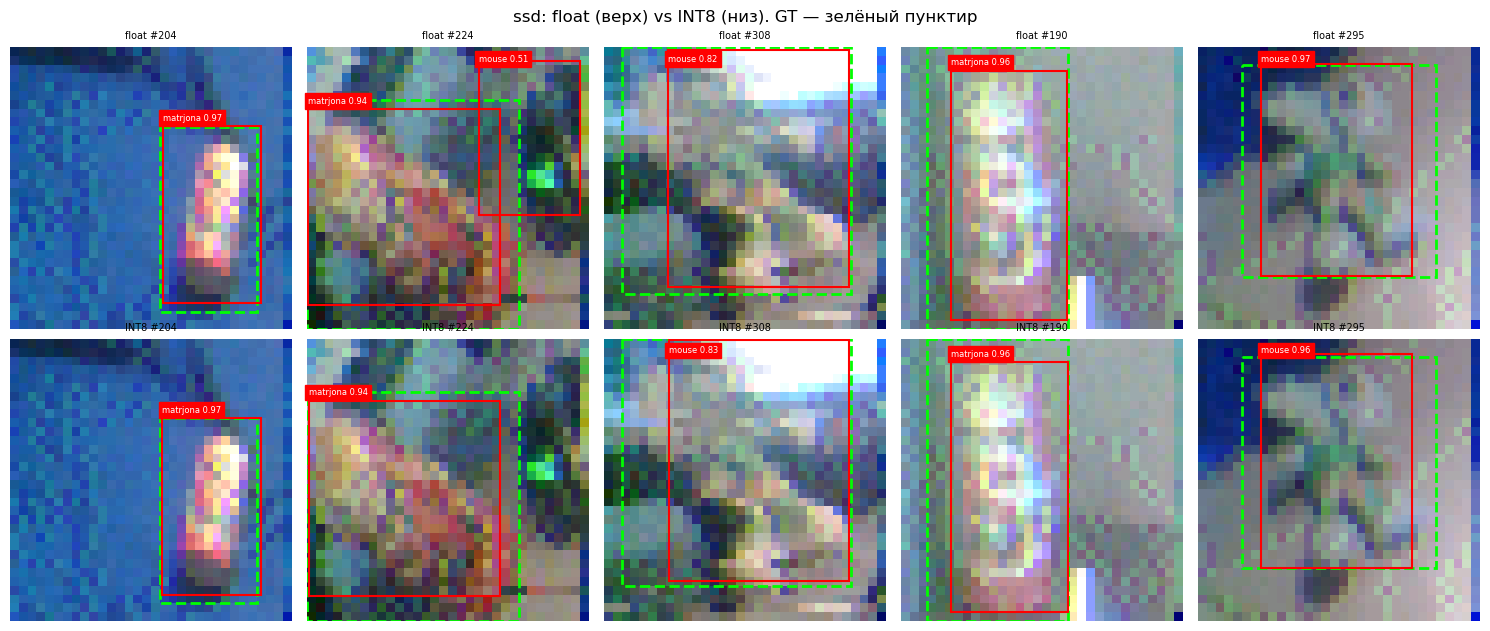

INT8 ошибочных кадров на test: 57 из 330


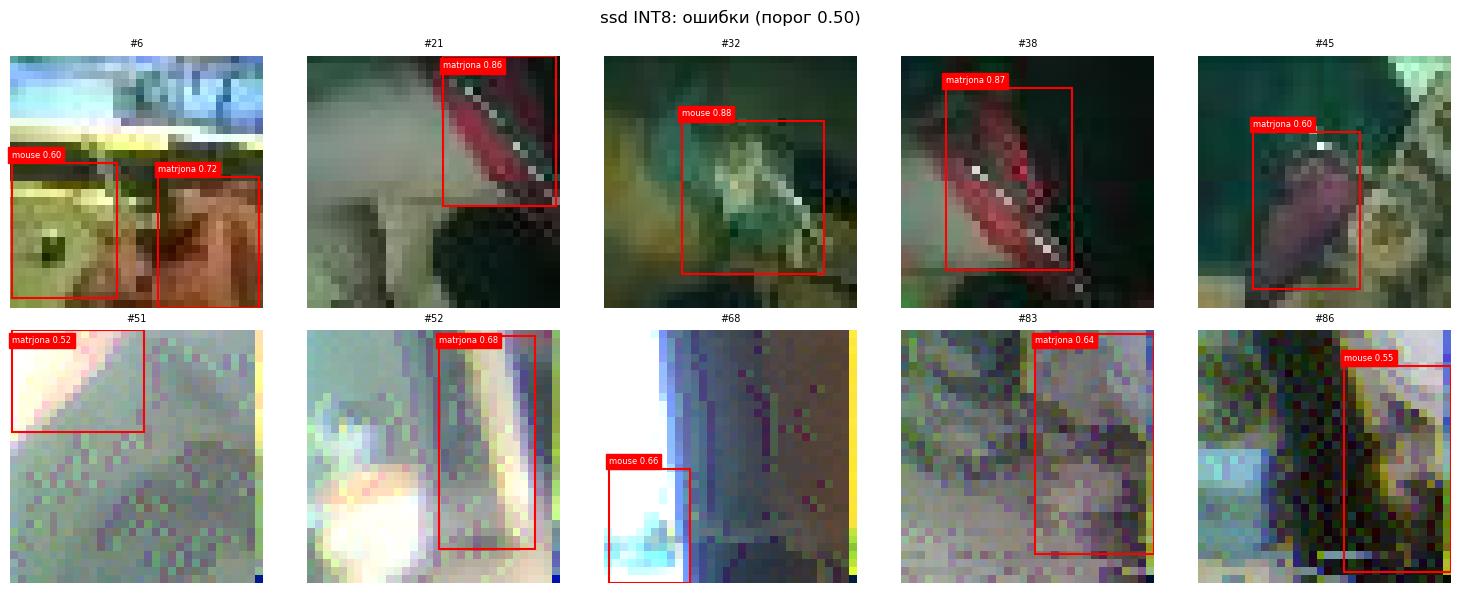

In [20]:
tr = trainers[BEST_ARCH]; thr = OP_THR[BEST_ARCH]
dets_q = decode_batch(BEST_ARCH, tfl_det[BEST_ARCH].predict(test_data["images"])); dets_f = predict_float(tr, test_data)
idx = np.random.default_rng(7).choice(len(test_data["images"]), 5, replace=False)
fig, ax = plt.subplots(2, 5, figsize=(15, 6.4))
for c, i in enumerate(idx):
    for r, (dd, nm) in enumerate(((dets_f, "float"), (dets_q, "INT8"))):
        k = dd[i]["scores"] >= thr
        draw(ax[r, c], test_data["images"][i], test_data["boxes"][i], test_data["labels"][i],
             dict(boxes=dd[i]["boxes"][k], scores=dd[i]["scores"][k], labels=dd[i]["labels"][k]), f"{nm} #{i}")
fig.suptitle(f"{BEST_ARCH}: float (верх) vs INT8 (низ). GT — зелёный пунктир"); plt.tight_layout(); plt.show()
_eq = [i for i in range(len(test_data["images"])) if is_error(dets_q[i], test_data["boxes"][i], test_data["labels"][i], thr)]
print(f"INT8 ошибочных кадров на test: {len(_eq)} из {len(test_data['images'])}")
if _eq: show_grid(test_data, dets_q, _eq[:10], thr, f"{BEST_ARCH} INT8: ошибки (порог {thr:.2f})")

# Шаг 11. Экспорт для Zephyr/TFLM
Данный блок кода реализует финальный шаг экпорта модели для микроконтроллеров и ОС реального времени Zephyr RTOS. Модуль автоматизирует упаковку квантованного файла .tflite в C++ заголовочник (model.hpp), генерацию детального конфигурационного файла с константами, параметрами квантования и анхорами (detector_config.h), а также создание фрагментов кода для регистрации необходимых математических операций в среде TFLM (TensorFlow Lite for Microcontrollers) без использования динамической памяти.

### Указываем модель для переноса на микроконтроллер.

In [ ]:
# Указываем модель для переноса на микроконтроллер.
EXPORT_ARCH = "ssd"
# EXPORT_ARCH = "ttf"   

In [26]:
# Функция конвертирует бинарный файл модели .tflite (переданный как байтовый массив blob) в заголовочный файл на языке C++ (.hpp).
def tflite_to_hpp(blob, path, name="g_model"):
    hexes = [f"0x{b:02x}" for b in blob]
    lines = [", ".join(hexes[i:i + 16]) for i in range(0, len(hexes), 16)]
    txt = (f"/* автогенерация TFL-Detection.ipynb; sha1={hashlib.sha1(blob).hexdigest()[:12]} */\n#pragma once\n"
           f"alignas(16) const unsigned char {name}[] = {{\n  " + ",\n  ".join(lines) + f"\n}};\nconst unsigned int {name}_len = {len(blob)};\n")
    Path(path).write_text(txt)

# Функция генерирует конфигурационный заголовочный файл (detector_config.h) для микроконтроллера, 
# содержащий все необходимые константы и параметры для работы модели.
def write_detector_config(path, arch, labels, in_scale, in_zp, out_cls_idx, out_box_idx, post, ssd_anchors=None,
                          variances=None, grid=None, in_hw=(32, 32)):
    L_ = ["/* автогенерация TFL-Detection.ipynb — не править вручную */", "#ifndef DETECTOR_CONFIG_H_", "#define DETECTOR_CONFIG_H_", "",
          "#define DET_ARCH_SSD 1", "#define DET_ARCH_TTF 2", f"#define DET_ARCH DET_ARCH_{arch.upper()}", "",
          f"#define DET_NUM_CLASSES {len(labels)}", f"#define DET_INPUT_W {in_hw[1]}", f"#define DET_INPUT_H {in_hw[0]}",
          f"#define DET_INPUT_SCALE {float(in_scale):.9g}f", f"#define DET_INPUT_ZERO_POINT {int(in_zp)}",
          "/* квантование входа: q = clamp(round(pix/255/DET_INPUT_SCALE) + DET_INPUT_ZERO_POINT, -128, 127) */", "",
          f"/* индексы выходных тензоров интерпретатора: interpreter->output(i) */", f"#define DET_OUT_CLS_IDX {int(out_cls_idx)}",
          f"#define DET_OUT_BOX_IDX {int(out_box_idx)}", "",
          f"#define DET_CONF_THR {float(post['op_thr']):.4f}f", f"#define DET_NMS_IOU {float(post['nms_iou']):.4f}f",
          f"#define DET_PRE_NMS_TOPK {int(post['pre_nms_topk'])}", f"#define DET_MAX_DET {int(post['max_det'])}", "",
          "static const char *const DET_LABELS[DET_NUM_CLASSES] = {" + ", ".join(f'"{l}"' for l in labels) + "};", ""]
    if arch == "ssd":
        A = len(ssd_anchors); L_ += [f"#define DET_NUM_ANCHORS {A}", "static const float DET_VAR[4] = {" + ", ".join(f"{v:.6g}f" for v in variances) + "};",
                                     "/* anchors: cx, cy, w, h в долях кадра; порядок (строка, столбец, anchor), уровни подряд */",
                                     "static const float DET_ANCHORS[DET_NUM_ANCHORS][4] = {"]
        L_ += ["  {" + ", ".join(f"{v:.8g}f" for v in a) + "}," for a in ssd_anchors] + ["};"]
    else:
        L_ += [f"#define DET_GRID_H {grid[0]}", f"#define DET_GRID_W {grid[1]}"]
    L_ += ["", "#endif /* DETECTOR_CONFIG_H_ */", ""]
    Path(path).write_text("\n".join(L_))

# Словарь соответствий между стандартными операциями TensorFlow Lite и 
# методами C++ класса MicroMutableOpResolver в библиотеке TensorFlow Lite for Microcontrollers.
TFLM_OP = {"CONV_2D": "AddConv2D", "DEPTHWISE_CONV_2D": "AddDepthwiseConv2D", "MAX_POOL_2D": "AddMaxPool2D", "AVERAGE_POOL_2D": "AddAveragePool2D",
           "ADD": "AddAdd", "RESHAPE": "AddReshape", "CONCATENATION": "AddConcatenation", "RESIZE_NEAREST_NEIGHBOR": "AddResizeNearestNeighbor",
           "QUANTIZE": "AddQuantize", "DEQUANTIZE": "AddDequantize", "PAD": "AddPad", "RELU": "AddRelu", "RELU6": "AddRelu6", "LOGISTIC": "AddLogistic",
           "SOFTMAX": "AddSoftmax", "FULLY_CONNECTED": "AddFullyConnected", "MEAN": "AddMean", "TRANSPOSE": "AddTranspose", "STRIDED_SLICE": "AddStridedSlice",
           "PACK": "AddPack", "SHAPE": "AddShape", "MUL": "AddMul", "SUB": "AddSub", "EXP": "AddExp"}

# Функция генерирует фрагмент кода на C++ для регистрации только тех операций, которые задействованы в конкретной модели.
def resolver_snippet(op_names):
    ops = sorted(set(op_names)); unknown = [o for o in ops if o not in TFLM_OP]
    body = "\n".join(f"\tmicro_op_resolver.{TFLM_OP[o]}();" for o in ops if o in TFLM_OP)
    s = f"static tflite::MicroMutableOpResolver<{len(ops) - len(unknown)}> micro_op_resolver;\n{body}"
    return s + (f"\n/* ВНИМАНИЕ: нет сопоставления для {unknown} — добавить вручную */" if unknown else "")

In [27]:
# Функция извлекает список всех операций (слоев), которые используются в данной .tflite модели.
def interpreter_ops(blob):
    it = tf.lite.Interpreter(model_content=blob)
    try: return [d["op_name"] for d in it._get_ops_details()]
    except Exception as e:
        print("(_get_ops_details недоступен:", e, ")"); return []

# Функция вычисляет грубую нижнюю оценку размера тензорной арены (tensor_arena) — объема оперативной памяти (RAM), 
# необходимого микроконтроллеру для хранения промежуточных активаций (данных, передаваемых между слоями во время работы сети).
def arena_lower_bound(blob):
    """Грубая НИЖНЯЯ оценка: max по операциям суммы размеров входных+выходных активаций (int8). Реальное значение — arena_used_bytes() на плате."""
    it = tf.lite.Interpreter(model_content=blob); it.allocate_tensors()
    det = {d["index"]: d for d in it.get_tensor_details()}; best = 0
    try: ops_ = it._get_ops_details()
    except Exception: return 0
    for op in ops_:
        ids = [i for i in list(op["inputs"]) + list(op["outputs"]) if i >= 0 and i in det and det[i]["shape"].size > 0 and "weights" not in det[i]["name"].lower()]
        sz = sum(int(np.prod(det[i]["shape"])) * np.dtype(det[i]["dtype"]).itemsize for i in ids); best = max(best, sz)
    return best

# # EXPORT_ARCH = BEST_ARCH            # можно переопределить вручную: "ssd" или "ttf"
tr, d = trainers[EXPORT_ARCH], tfl_det[EXPORT_ARCH]; blob = tflite_models[EXPORT_ARCH]
cls_idx, box_idx = d.order[0], d.order[1]
post = dict(CFG["post"], op_thr=OP_THR[EXPORT_ARCH])
# Конвертирует бинарный файл модели .tflite (переданный как байтовый массив blob) в заголовочный файл на языке C++ (.hpp).
tflite_to_hpp(blob, OUT_DIR / "model.hpp")
# Генерирует конфигурационный заголовочный файл (detector_config.h) для микроконтроллера.
write_detector_config(OUT_DIR / "detector_config.h", EXPORT_ARCH, FG, d.in_scale, d.in_zp, cls_idx, box_idx, post,
                      ssd_anchors=ANC_CXCYWH if EXPORT_ARCH == "ssd" else None, variances=SSD_C["variances"], grid=FEAT_SHAPES[0])
# Извлекает список всех операций (слоев), которые используются в данной .tflite модели.
ops = interpreter_ops(blob)
print(f"\nЭкспорт {EXPORT_ARCH}: модель {len(blob) / 1024:.1f} КБ | операции: {sorted(set(ops))}")
print("Нижняя оценка арены: ~%.1f КБ (реальное значение смотрите в логе 'arena used'; допустимо до 100 КБ)" % (arena_lower_bound(blob) / 1024))
print("\n// --- для tflm_wrapper.cpp ---\n" + resolver_snippet(ops))
print(f"\nФайлы в {OUT_DIR.resolve()}: model.hpp, detector_config.h, detector_{EXPORT_ARCH}_int8.tflite")


Экспорт ttf: модель 45.5 КБ | операции: ['ADD', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'MAX_POOL_2D', 'RESIZE_NEAREST_NEIGHBOR']
Нижняя оценка арены: ~25.0 КБ (реальное значение смотрите в логе 'arena used'; допустимо до 100 КБ)

// --- для tflm_wrapper.cpp ---
static tflite::MicroMutableOpResolver<5> micro_op_resolver;
	micro_op_resolver.AddAdd();
	micro_op_resolver.AddConv2D();
	micro_op_resolver.AddDepthwiseConv2D();
	micro_op_resolver.AddMaxPool2D();
	micro_op_resolver.AddResizeNearestNeighbor();

Файлы в C:\Users\STEPANJUK\Desktop\TFL\TensorFlowLite\TFL_Detection\export: model.hpp, detector_config.h, detector_ttf_int8.tflite


#### Блок кода генерирует файлы реализации на языке С:
Заголовочный файл det_postprocess.h и файл реализации det_postprocess.c, которые выполняют постпроцессинг (обработку результатов) для квантованных INT8-моделей детекции объектов (SSD и TTF) для запуска на микроконтроллерах (в составе TensorFlow Lite for Microcontrollers).

In [28]:
DET_POSTPROCESS_H = r'''/*
 * det_postprocess.h — постпроцессинг детектора (SSD / TTF) для TFLM-int8 моделей.
 * Без динамической памяти, без libm кроме expf/logf. Конфигурация — в detector_config.h
 * (генерируется ноутбуком TFL-Detection.ipynb вместе с model.hpp).
 */
#ifndef DET_POSTPROCESS_H_
#define DET_POSTPROCESS_H_

#include <stdint.h>

#ifdef __cplusplus
extern "C" {
#endif

/* Результат детекции: координаты нормированы в [0,1] относительно входного кадра (x вправо, y вниз). */
typedef struct {
	float x1, y1, x2, y2;
	float score;
	int   label;      /* 0-based индекс переднего плана: DET_LABELS[label] */
} det_t;

/* int8-тензор модели вместе с параметрами квантования (output->data.int8, params.scale, params.zero_point). */
typedef struct {
	const int8_t *data;
	float         scale;
	int           zero_point;
} det_tensor_t;

/*
 * SSD: cls = логиты [DET_NUM_ANCHORS][DET_NUM_CLASSES+1] (индекс 0 — фон), box = дельты [DET_NUM_ANCHORS][4].
 * TTF: cls = heatmap-логиты [H][W][DET_NUM_CLASSES],       box = ltrb      [H][W][4] (доли кадра, >=0).
 * Возвращает число детекций (<= max_out), отсортированных по убыванию score.
 */
int det_postprocess(const det_tensor_t *cls, const det_tensor_t *box, det_t *out, int max_out);

#ifdef __cplusplus
}
#endif

#endif /* DET_POSTPROCESS_H_ */
'''

DET_POSTPROCESS_C = r'''#include "det_postprocess.h"
#include "detector_config.h"

#include <math.h>

#define DET_DELTA_CLIP 2.5f

typedef struct {
	float score;
	int   label;
	int   idx;        /* SSD: индекс anchor; TTF: i*W+j */
} cand_t;

static inline float deq(const det_tensor_t *t, int i)
{
	return ((float)((int)t->data[i] - t->zero_point)) * t->scale;
}

static inline float clamp01(float v)
{
	return v < 0.0f ? 0.0f : (v > 1.0f ? 1.0f : v);
}

/* Вставка в массив, отсортированный по убыванию score; при равенстве — после уже имеющихся (стабильно). */
static void cand_insert(cand_t *c, int *n, int cap, float score, int label, int idx)
{
	int pos = *n;
	if (*n == cap) {
		if (!(score > c[cap - 1].score)) {
			return;
		}
		pos = cap - 1;           /* вытесняем последний */
	} else {
		(*n)++;
	}
	while (pos > 0 && c[pos - 1].score < score) {
		c[pos] = c[pos - 1];
		pos--;
	}
	c[pos].score = score; c[pos].label = label; c[pos].idx = idx;
}

static float box_iou(const det_t *a, const det_t *b)
{
	float iw = fminf(a->x2, b->x2) - fmaxf(a->x1, b->x1);
	float ih = fminf(a->y2, b->y2) - fmaxf(a->y1, b->y1);
	if (iw <= 0.0f || ih <= 0.0f) {
		return 0.0f;
	}
	float inter = iw * ih;
	float aa = fmaxf(a->x2 - a->x1, 0.0f) * fmaxf(a->y2 - a->y1, 0.0f);
	float ab = fmaxf(b->x2 - b->x1, 0.0f) * fmaxf(b->y2 - b->y1, 0.0f);
	float u = aa + ab - inter;
	return inter / (u > 1e-9f ? u : 1e-9f);
}

/* Жадный NMS внутри класса. dets[] уже отсортирован по убыванию score. Результат уплотняется в начале массива. */
static int nms_classwise(det_t *d, int n, float iou_thr, int max_out)
{
	uint8_t sup[DET_PRE_NMS_TOPK] = {0};
	int k = 0;
	for (int i = 0; i < n && k < max_out; i++) {
		if (sup[i]) {
			continue;
		}
		for (int j = i + 1; j < n; j++) {
			if (!sup[j] && d[j].label == d[i].label && box_iou(&d[i], &d[j]) > iou_thr) {
				sup[j] = 1;
			}
		}
		d[k++] = d[i];
	}
	return k;
}

#if DET_ARCH == DET_ARCH_SSD
/* ------------------------------------------ SSD ------------------------------------------ */
int det_postprocess(const det_tensor_t *cls, const det_tensor_t *box, det_t *out, int max_out)
{
	cand_t cand[DET_PRE_NMS_TOPK];
	int nc = 0;
	const int K = DET_NUM_CLASSES + 1;

	for (int a = 0; a < DET_NUM_ANCHORS; a++) {
		float l[DET_NUM_CLASSES + 1], m, s = 0.0f;
		for (int k = 0; k < K; k++) {
			l[k] = deq(cls, a * K + k);
		}
		m = l[0];
		for (int k = 1; k < K; k++) {
			if (l[k] > m) { m = l[k]; }
		}
		for (int k = 0; k < K; k++) {
			l[k] = expf(l[k] - m); s += l[k];
		}
		for (int c = 1; c < K; c++) {
			float p = l[c] / s;
			if (p >= DET_CONF_THR) {
				cand_insert(cand, &nc, DET_PRE_NMS_TOPK, p, c - 1, a);
			}
		}
	}

	static det_t tmp[DET_PRE_NMS_TOPK];
	for (int i = 0; i < nc; i++) {
		const int a = cand[i].idx;
		const float *an = DET_ANCHORS[a];
		float d0 = deq(box, a * 4 + 0), d1 = deq(box, a * 4 + 1), d2 = deq(box, a * 4 + 2), d3 = deq(box, a * 4 + 3);
		float cx = an[0] + d0 * DET_VAR[0] * an[2];
		float cy = an[1] + d1 * DET_VAR[1] * an[3];
		float sw = d2 * DET_VAR[2], sh = d3 * DET_VAR[3];
		sw = sw < -DET_DELTA_CLIP ? -DET_DELTA_CLIP : (sw > DET_DELTA_CLIP ? DET_DELTA_CLIP : sw);
		sh = sh < -DET_DELTA_CLIP ? -DET_DELTA_CLIP : (sh > DET_DELTA_CLIP ? DET_DELTA_CLIP : sh);
		float w = an[2] * expf(sw), h = an[3] * expf(sh);
		tmp[i].x1 = clamp01(cx - 0.5f * w); tmp[i].y1 = clamp01(cy - 0.5f * h);
		tmp[i].x2 = clamp01(cx + 0.5f * w); tmp[i].y2 = clamp01(cy + 0.5f * h);
		tmp[i].score = cand[i].score; tmp[i].label = cand[i].label;
	}

	int n = nms_classwise(tmp, nc, DET_NMS_IOU, max_out < DET_MAX_DET ? max_out : DET_MAX_DET);
	for (int i = 0; i < n; i++) {
		out[i] = tmp[i];
	}
	return n;
}

#elif DET_ARCH == DET_ARCH_TTF
/* ------------------------------------------ TTF ------------------------------------------ */
int det_postprocess(const det_tensor_t *cls, const det_tensor_t *box, det_t *out, int max_out)
{
	cand_t cand[DET_PRE_NMS_TOPK];
	int nc = 0;
	const int H = DET_GRID_H, W = DET_GRID_W, C = DET_NUM_CLASSES;
	/* порог по логиту: sigmoid(v) >= thr  <=>  v >= ln(thr/(1-thr)) */
	const float thr_logit = logf(DET_CONF_THR / (1.0f - DET_CONF_THR));

	for (int i = 0; i < H; i++) {
		for (int j = 0; j < W; j++) {
			for (int c = 0; c < C; c++) {
				float v = deq(cls, (i * W + j) * C + c);
				if (v < thr_logit) {
					continue;
				}
				int is_peak = 1;
				for (int di = -1; di <= 1 && is_peak; di++) {
					for (int dj = -1; dj <= 1; dj++) {
						int ni = i + di, nj = j + dj;
						if ((di == 0 && dj == 0) || ni < 0 || nj < 0 || ni >= H || nj >= W) {
							continue;
						}
						if (deq(cls, (ni * W + nj) * C + c) > v) { is_peak = 0; break; }
					}
				}
				if (is_peak) {
					cand_insert(cand, &nc, DET_PRE_NMS_TOPK, 1.0f / (1.0f + expf(-v)), c, i * W + j);
				}
			}
		}
	}

	static det_t tmp[DET_PRE_NMS_TOPK];
	for (int k = 0; k < nc; k++) {
		const int i = cand[k].idx / W, j = cand[k].idx % W;
		float l = fmaxf(deq(box, cand[k].idx * 4 + 0), 0.0f), t = fmaxf(deq(box, cand[k].idx * 4 + 1), 0.0f);
		float r = fmaxf(deq(box, cand[k].idx * 4 + 2), 0.0f), b = fmaxf(deq(box, cand[k].idx * 4 + 3), 0.0f);
		float cx = ((float)j + 0.5f) / (float)W, cy = ((float)i + 0.5f) / (float)H;
		tmp[k].x1 = clamp01(cx - l); tmp[k].y1 = clamp01(cy - t);
		tmp[k].x2 = clamp01(cx + r); tmp[k].y2 = clamp01(cy + b);
		tmp[k].score = cand[k].score; tmp[k].label = cand[k].label;
	}

	int n = nms_classwise(tmp, nc, DET_NMS_IOU, max_out < DET_MAX_DET ? max_out : DET_MAX_DET);
	for (int k = 0; k < n; k++) {
		out[k] = tmp[k];
	}
	return n;
}
#else
#error "DET_ARCH must be DET_ARCH_SSD or DET_ARCH_TTF (see detector_config.h)"
#endif
'''

(OUT_DIR / 'det_postprocess.h').write_text(DET_POSTPROCESS_H)
(OUT_DIR / 'det_postprocess.c').write_text(DET_POSTPROCESS_C)
print('Записаны det_postprocess.h/.c в', OUT_DIR.resolve())

Записаны det_postprocess.h/.c в C:\Users\STEPANJUK\Desktop\TFL\TensorFlowLite\TFL_Detection\export


# Шаг 12. Интеграция в Zephyr-проект
1. Положить `model.hpp`, `detector_config.h`, `det_postprocess.[ch]` в проект
2. В `tflm_wrapper.cpp` заменить op-resolver на сгенерированный выше;
3. `kTensorArenaSize` — начать с 40–48 КБ, затем посмотреть `interpreter.arena_used_bytes()` и уменьшить.

# Учебное пособие:

### TensorFlow:
##### ESP32-CAM 15: TensorFlow LITE классификация изображений
https://www.youtube.com/watch?v=ORJrzHiHIDc&t=660s

https://vkvideo.ru/video63898488_456239464?pl=63898488_-2

##### ESP32 + CatBoost: Decision Trees for Color Classification (GY-31-TCS230)
https://www.youtube.com/watch?v=CmU3OemU6gk

https://vkvideo.ru/video-229753773_456239017

##### ESP32 + KNN: Метод K-ближайших соседей для классификации цветов (GY-31-TCS230)
https://www.youtube.com/watch?v=0kSWgAhEtCI

https://www.youtube.com/watch?v=0kSWgAhEtCI

##### ESP32 + TensorFlow Lite: Линейная модель для классификации цветов (GY-31-TCS230)
https://www.youtube.com/watch?v=DyiEhkdACyw

https://vkvideo.ru/video-229753773_456239019

##### ESP32 + LD2410: Линейная модель для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=ds3CPqLV-MI

https://www.youtube.com/watch?v=ds3CPqLV-MI

##### ESP32 + LD2410: Сверточная нейронная сеть для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=kC0A1RCqdIc

https://vkvideo.ru/video-229753773_456239021

##### ESP32 + LD2410: Рекуррентная нейронная сеть для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=UZd4lkwPL3Q&t=1s

https://vkvideo.ru/video-229753773_456239022

##### ESP32 + LD2410: Трансформер и механизм внимания для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=cPqogs8ARUU

https://vkvideo.ru/video-229753773_456239023

##### ESP32: распознавание речи нейросетью (TensorFlow Lite)
https://www.youtube.com/watch?v=IH22K1WFqjU

https://vkvideo.ru/video-229753773_456239025



### Введение в машинное обучение:
##### Лекция. Введение в машинное обучение.
https://www.youtube.com/watch?v=LcvKd42DGQU

https://vkvideo.ru/video-155161349_456239164

##### Семинар. Введение в машинное обучение.
https://www.youtube.com/watch?v=YMtsgx8oB24

### Линейные модели:
##### Лекция 2.1: Линейная регрессия.
https://www.youtube.com/watch?v=khdaLtu9i-s

https://vkvideo.ru/video-155161349_456239169

##### Лекция 2.2: LogLoss.
https://www.youtube.com/watch?v=HV4Bm8UJwIs

https://vkvideo.ru/video-155161349_456239170

##### Лекция. Логистическая регрессия
https://www.youtube.com/watch?v=twdZBko9vH4

##### Лекция. Градиентный спуск в линейных алгоритмах
https://www.youtube.com/watch?v=N5_VAN1nhm8

https://vkvideo.ru/video-155161349_456239172

##### Лекция. Регуляризация в линейной регрессии
https://www.youtube.com/watch?v=L_o8v5A23XA

https://vkvideo.ru/video-155161349_456239173

##### Лекция 2.6: Нормализация.
https://www.youtube.com/watch?v=tOiwAyilk3I

https://vkvideo.ru/video-155161349_456239174

##### Семинар. Линейная и логистическая регрессия
https://www.youtube.com/watch?v=5VOp5xmBvds

https://vkvideo.ru/video-155161349_456239177

##### Семинар. Регуляризация в линейной регрессии
https://www.youtube.com/watch?v=56YdhX0xj3k

https://vkvideo.ru/video-155161349_456239176

### Выбор модели:
##### Метрики машинного обучения
https://www.youtube.com/watch?v=TaTGunOAIK4

https://vkvideo.ru/video-155161349_456239195

##### Лекция. Решающие деревья
https://www.youtube.com/watch?v=MJwAoWFTMWw

https://vkvideo.ru/video-155161349_456239192

##### Лекция. Композиции алгоритмов
https://www.youtube.com/watch?v=vqF8wrWjR5s

https://vkvideo.ru/video-155161349_456239193

##### Лекция. Градиентный бустинг
https://www.youtube.com/watch?v=JElfEE1OrSU

##### Семинар. Model Selection
https://www.youtube.com/watch?v=B03CrtpYDi4

### Основы PyTorch:
##### Введение в нейронные сети. Часть 1. История развития Deep Learning
https://www.youtube.com/watch?v=ZfXpX8tMg-w

https://vkvideo.ru/video-155161349_456239204

##### Введение в нейронные сети. Часть 2. Механизм обратного распространения ошибки
https://www.youtube.com/watch?v=-yiq1DRX9K0

https://vkvideo.ru/video-155161349_456239205

##### Введение в нейронные сети. Часть 3. Функции активации. Краткий обзор применений CNN и RNN
https://www.youtube.com/watch?v=3F7rydcAa0w

https://vkvideo.ru/video-155161349_456239207

##### Лекция. Полносвязная нейронная сеть
https://www.youtube.com/watch?v=O0nGKKFyYT4

https://vkvideo.ru/video-155161349_456239206

##### Семинар. Введение в библиотеку Pytorch
https://www.youtube.com/watch?v=DU3-mc8qFxA

##### Семинар. Нейронная сеть на Pytorch
https://www.youtube.com/watch?v=1aOp0pOvczg

### Полносвязные и свёрточные нейронные сети:
##### Лекция. История развития сверточных нейронных сетей
https://www.youtube.com/watch?v=Xq76hQHCkvQ

https://vkvideo.ru/video-155161349_456239213

##### Лекция. Сверточные нейронные сети
https://www.youtube.com/watch?v=HpKGv-kYurk

https://vkvideo.ru/video-155161349_456239214

##### Лекция. Пулинг. Операция пулинга
https://www.youtube.com/watch?v=IxLuPHtZBTY

##### Лекция. Задачи компьютерного зрения
https://www.youtube.com/watch?v=3IPRcBIsgNA

https://vkvideo.ru/video-155161349_456239216

##### Семинар. Свёртка. Пулинг
https://www.youtube.com/watch?v=6TMeFrRCJ_0

https://vkvideo.ru/video-155161349_456239217

##### Семинар. Модули в PyTorch
https://www.youtube.com/watch?v=0R65rYFZe6U

https://vkvideo.ru/video-155161349_456239218

##### Семинар. Свёрточные сети.
https://www.youtube.com/watch?v=xgVr9vISm8w

### Пакетная нормализация, исключение (dropout), оптимизаторы:
##### Лекция. Градиентная оптимизация в Deep Learning
https://www.youtube.com/watch?v=6CvpMOO-DB4

https://vkvideo.ru/video-155161349_456239227

##### Лекция. Регуляризация в Deep Learning
https://www.youtube.com/watch?v=x72-oUjv1ew

https://vkvideo.ru/video-155161349_456239228

##### Семинар. PyTorch. Batch Normalization и Dropout
https://www.youtube.com/watch?v=Y9a5EfqM7RM

##### Семинар. PyTorch. Оптимизаторы
https://www.youtube.com/watch?v=Yh1VoUhS5MY

https://vkvideo.ru/video-155161349_456239230

### Cвёрточные нейронные сети:
##### Лекция. Архитектуры CNN
https://www.youtube.com/watch?v=TcUPuKpIlhQ

https://vkvideo.ru/video-155161349_456239232

##### Лекция. Transfer Learning
https://www.youtube.com/watch?v=oLpREso27Zw

https://vkvideo.ru/video-155161349_456239233

##### Семинар. Transfer Learning в компьютерном зрении
https://www.youtube.com/watch?v=4AUxDH4doV0

### Семантическая сегментация:
##### Семантическая сегментация. Введение
https://www.youtube.com/watch?v=tIqndofykgc

https://vkvideo.ru/video-155161349_456239239

##### Семантическая сегментация. Трюки: Deconvolution, Dilated Convolution
https://www.youtube.com/watch?v=K73tZxH9nvE

https://vkvideo.ru/video-155161349_456239240

##### Семантическая сегментация. Архитектура UNet
https://www.youtube.com/watch?v=yEuIV5FsRMs

https://vkvideo.ru/video-155161349_456239241

### Детекция объектов:
##### Лекция. Нейронная детекция объектов. Классификация (повторение).
https://www.youtube.com/watch?v=8D01Xo9hWgg

https://vkvideo.ru/video-155161349_456239244

##### Лекция. Нейронная детекция объектов. Основы.
https://www.youtube.com/watch?v=Y4JvVOaZWsU

https://vkvideo.ru/video-155161349_456239245

##### Лекция. Нейронная детекция объектов. Двухстадийные нейросети.
https://www.youtube.com/watch?v=WrKl7GHWilA

https://vkvideo.ru/video-155161349_456239246

##### Лекция. Нейронная детекция объектов. Одностадийные нейросети.
https://www.youtube.com/watch?v=OPK63uqAQLs

https://vkvideo.ru/video-155161349_456239247

##### Лекция. Нейронная детекция объектов. Современные подходы и задачи.
https://www.youtube.com/watch?v=6WXUNNYysww

https://vkvideo.ru/video-155161349_456239249

##### Практика. Нейронная детекция объектов. Запуск SSD, TorchHub.
https://www.youtube.com/watch?v=JX6N74K84n0

##### Практика. Нейронная детекция объектов. Обучение SSD, mmdetection.
https://www.youtube.com/watch?v=gw_IXcbhOO0

https://vkvideo.ru/video-155161349_456239251

### Автоэнкодеры:
##### Лекция. Генеративные модели, автоэнкодеры
https://www.youtube.com/watch?v=6qVfC7P9dEc

https://vkvideo.ru/video-155161349_456239260

##### Семинар. Автоэнкодеры
https://vkvideo.ru/video-155161349_456239258

https://www.youtube.com/watch?v=FUXsks9SPOQ

##### Семинар. VAE
https://www.youtube.com/watch?v=mqPw5Lm810o

### Генеративные модели:
##### Лекция. Генеративные модели. Генеративно-состязательные сети
https://www.youtube.com/watch?v=An20DOEOctc

##### Семинар. Генеративные модели. Генеративно-состязательные сети
https://www.youtube.com/watch?v=Anocy4ey0vs